# The Prompt Is Not the Author

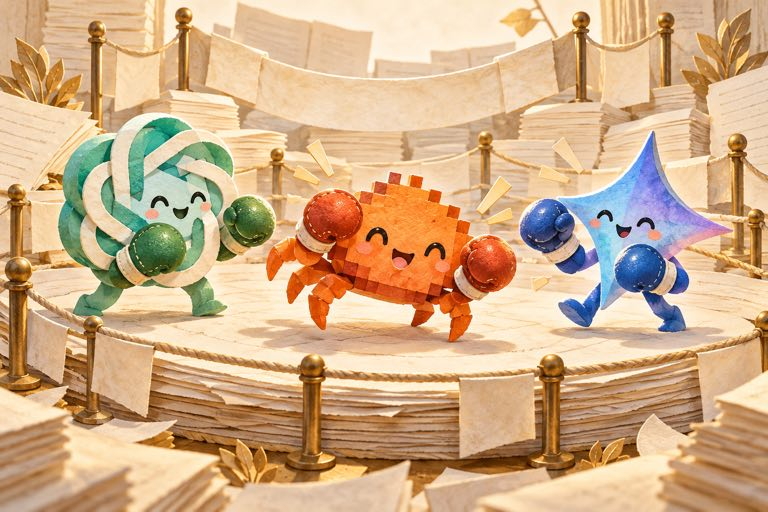

*Different voices, one friendly arena. Original AI-generated fan art; no endorsement implied.*

**Read the topic. Listen for the voice. Test both assumptions.**

This notebook combines strong credited public methods with our own shared-prompt Gaussian heads and independently trained two-stage adapters. It is an inference notebook: frozen features and public checkpoints produce complementary evidence; inferred prompt groups help remove shared content; the result is an 18-author prediction for each passage.

Numbers in linked public notebook titles are their authors' reported historical results. They are distinct from the native results explicitly identified for our own notebook below.

The verified results of this notebook's own submissions: version 3 0.599, **version 4 0.604** (COMPLETE submission `57428928`, [native version 4](https://www.kaggle.com/code/prvsiyan/the-prompt-is-not-the-author?scriptVersionId=360252286)), version 5 0.603 (submission `57436243`) and Kaggle version 12, the first run of the version-6 design: **0.622**. Kaggle versions 6 to 8 were editorial editions of the version-5 code (illustrations and reader corrections, no new score); versions 9 to 11 failed in their runs and were never submitted. This version is the version-7 design described below with the illustrated narrative restored; its own score is recorded in the lineage table once its submission completes. The illustrations and diagrams are explanations, not evidence of a score gain.

| If you want to… | Read… |
|---|---|
| understand the main failure mode | the pair-centering derivation and [Gaussian model](#instyle-gaussian) |
| reproduce the public lineage | the [member-by-member credits](#instyle-lineage-credits) and attached inputs |
| see our additions | [Gaussian heads](#instyle-gaussian) on every member, [our two-stage seeds](#instyle-two-stage), the end-token check, and the validation notes |
| understand transduction | [grouping](#instyle-groups) and the [balancing caveat](#instyle-balancing) |
| explore the next hypothesis | the [final research questions](#instyle-limitations); none are enabled silently |

<a id="instyle-lineage"></a>

## Method lineage and version history

*Versions 2 to 13 (two branches).* Version 1 of this notebook (public LB **0.569**) was a from-scratch re-implementation of Travis Nguyen's [NTL lora instyle | 0.563](https://www.kaggle.com/code/vnton37nguyn/ntl-lora-instyle-0-563-please-vote-me) plus our shared-prompt Gaussian group heads. Version 2 adds a second branch: Nishant Dahal's [Two-stage LoRA on the public pool](https://www.kaggle.com/code/nishantdahal/two-stage-lora-on-the-public-pool) (public LB 0.592), whose two checkpoints he has since [published](https://www.kaggle.com/datasets/nishantdahal/ntl-two-stage-lora). The two branches are mixed 85/15 and balanced once, the design Кирилл Тымчишин found in his [0.600 fork](https://www.kaggle.com/code/kirilltym/0-600-teach-the-model-remove-the-prompt) of the two, together with his shared-prompt Gaussian head on the 8B LoRA features. Version 2 also adds Zbigniew Kirchner's public [in-style Qwen3-8B LoRA](https://www.kaggle.com/datasets/zbigniewkirchner/ntl-qwen3-8b-lora-instyle) to branch B (his fork of version 1 reached 0.574), Versions 2 and 3 gave branch A this notebook's mixed content + GLM grouping of the test pool (0.593 and see below); from version 4 each branch keeps the grouping its members were tuned with: content-only TF-IDF clusters cut at 0.85 for branch A, content + GLM for branch B. Version 3 adds our own re-training of the two-stage recipe (a 38,642-passage pool we built from fifteen public datasets, our own trainer, two seeds) to branch A.

| Version | What changed | Public LB |
|---|---|---|
| 1 | the 0.563 stack re-implemented + 4 shared-prompt Gaussian group heads | 0.569 |
| 2 | + branch A: the public two-stage 8B and 14B LoRAs, pool SVC, Gaussian head on the 8B features; 85/15 mix; in-style LoRA in branch B | 0.593 |
| 3 | + our own two-stage LoRAs (two seeds, own pool and trainer) in branch A | 0.599 |
| 4 | + a shared-prompt Gaussian head on every two-stage LoRA's features (14B and our two seeds, not only the 8B); branch A back on its own TF-IDF grouping | **0.604** |
| 5 | + the frozen Qwen3-4B early-layer classifier of Joseph Adamski's [0.596 notebook](https://www.kaggle.com/code/josephadamski91/two-stage-lora-atlas-and-early-layers) (layers 1-3, 10% of branch A), with test-side standardisation and its own Gaussian group head | 0.603 (dropped) |
| 13 | the v18 base + one own member: our full-pool two-stage seed (stage 1 on a class-balanced 54k subsample of part two's pool, stage 2 on the competition rows; prompt-grouped OOF 0.595 on folds 0-3 against 0.5675 for the earlier seeds, [adapters](https://www.kaggle.com/datasets/prvsiyan/ntl-two-stage-lora-adapters-v3)) at 0.20 plain and 0.10 twin in branch A | **0.622** |
| 12 | a control: branch A is part two's arithmetic alone (its four members and twins, no older 14B, no own seeds, no Gaussian heads in A), mixed 85/15 with our stack, ATLAS at margin 0.30: the exact 0.636 recipe, to locate the gap between versions 15/16 and that score | **0.639** (Kaggle version 18): our branch-A additions had cost 0.011, so this is the base from here on |
| 11 | + joint decoding of branch A's groups of 2 and 3 passages: the plain members' blend is the unary term, every Gaussian head's joint log-likelihood beyond its singletons is a coupling, and the posterior is exact over distinct-author label tuples (our Fable harness: +0.002 nested over the Gaussian heads alone) | **0.622** |
| 10 | the two knobs the 0.639 stack's author lists as the first things to try: branch B's share raised from 15% to 25% (its log-probability scale is sharper than branch A's, so 15% already under-counts it) and ATLAS extended to rows with a top-2 margin below 0.40 | **0.622** |
| 9 | + an anchor submission written as soon as branch A is complete (replaced by the full result at the end), after the 0.639 notebook's fail-safe; our two seeds retrained on part two's pool (class-balanced) with the normalised regenerations of the training prompts as extra stage-2 rows | **0.622** |
| 8 | the same design made to fit the 9-hour budget: model files are copied to local disk before loading (the dataset mounts cost version 7 three extra hours), and the Qwen3.5-9B token-attention head of branch B is dropped (its 18 GB backbone alone cost up to 1.9 hours for a small member of the 15% branch) | **0.622** |
| 7 | + ATLAS source-conditioned likelihoods (Joseph Adamski's public adapter, our own scorer) on the rows whose top-2 margin is below 0.30, most-uncertain first; every input now a public dataset or Kaggle model (branch B's frozen-model weights and small heads mirrored in [our dataset](https://www.kaggle.com/datasets/prvsiyan/ntl-branch-b-public-mirror-v1)) | **0.622** |
| 6 | branch A rebuilt on Nishant Dahal's [two-stage LoRA, part two](https://www.kaggle.com/code/nishantdahal/two-stage-lora-part-two) (0.620: Qwen3-14B and Qwen2.5-14B two-stage LoRAs, a two-stage fully fine-tuned DeBERTa-v3-large, the SVC on his 75,783-passage pool, all in his public [dataset](https://www.kaggle.com/datasets/nishantdahal/ntl-handwriting-blend)); a shared-prompt Gaussian head on every branch-A member; the older 14B and our own seeds kept at small weights; the training end token checked per checkpoint; 300-step Sinkhorn | **0.622** |

Every passage in this competition is an answer to a prompt, and the prompt leaves a mark on the text that is usually louder than the author's. Two passages about the same volcano look alike even if a GPT and a Gemini wrote them; two passages by the same model look different if one is about volcanoes and the other about tax law. The whole lineage of strong public notebooks is a series of ways to *subtract the prompt*: group the test passages that share a prompt, centre their features within the group, and classify what is left. This notebook keeps that recipe, replaces the finite-sample subtraction with a model that integrates the prompt effect out (section 4), and gives the strongest members more voices to learn from (section 5b).

<a id="instyle-lineage-credits"></a>

## What is kept from the 0.563 notebook (credit where it is due)

The structure below is the 0.563 notebook's, member by member, with the two-stage LoRAs and the in-style LoRA added as members. All of its public ingredients are reused through their public datasets and kernel outputs:

| Member | Origin |
|---|---|
| Style-aware character / word / shape / function-word n-grams with a LinearSVC, plus a prompt-centred twin on inferred test groups | Yang Kuang Ou's n-gram recipe; the centred twin from the 0.556/0.559 lineage; in-style extra passages (Seyit Kaan Güneş's Claude API passages, the free proxy generations of Lucas Boesen, Abdullah Afify and Do Phuc Hung, and prvsiyan's extended dataset) |
| Stylometric features with LightGBM | the same lineage |
| Frozen decoder states (Qwen3-8B-Base, Qwen2.5-7B, Qwen3-4B-Base, GLM-4-9B-0414), test-set standardised, with prompt-centred twins | Lucas Boesen's [LoRA x Adaptive Centering](https://www.kaggle.com/code/lucasboesen/lora-x-adaptive-centering) |
| Frozen bidirectional encoders (DeBERTa-v3-large, ELECTRA-large, desklib AI-text detector) | the same, with Rudra's frozen-encoder idea |
| Three LoRA classifiers on a 24-layer Qwen3-8B-Base trunk (Vladislav Lavrentev's public LoRA24, Lucas Boesen's seed-7 run, Zbigniew Kirchner's run with a within-Claude head) | their public checkpoints; the LoRA24 training kernel became private on 23 October, so version 7 takes that checkpoint from fle3n's public recovery copy, and the seed-7 run, the token-attention heads and the ELECTRA / desklib weights from a mirror dataset of the original public kernel outputs |
| A LoRA classifier on a 20-layer Qwen2.5-7B trunk trained on train + in-style passages | Travis Nguyen's [training kernel](https://www.kaggle.com/code/vnton37nguyn/ntl-train-lora-qwen25-instyle), the 0.563 notebook's own contribution |
| Learned token-attention heads on frozen Qwen3.5-9B layer 18 and DeBERTa-v3-large layer 23 | Кирилл Тымчишин's recipe, Lucas Boesen's training kernels |
| UltraBERT-380M 5-fold ensemble | pjmathematician |
| Test-pool grouping (content-word TF-IDF + GLM layer-24 cosine, average linkage), Sinkhorn class balancing, within-Claude and within-family gates | the 0.549 / 0.552 / 0.559 notebooks |

The blend weights are the 0.563 notebook's (fitted there by L-BFGS on prompt-grouped out-of-fold predictions). Nothing was re-tuned.

The branch-B member multipliers follow the 0.563 lineage; branch A follows the credited part-two recipe; the 85/15 integration follows the 0.600 fork. Our Gaussian and adapter additions have separately stated weights. The complete imported stack has not been certified here by a fresh nested two-scheme weight refit.

<a id="instyle-gaussian"></a>

## The Gaussian group heads (version 1's addition)

Prompt centring subtracts the **sample mean** of a detected group from each member. For two passages, the centred first feature is `(x1 - x2)/2`: the common additive prompt cancels, while the author's own contribution has coefficient one half and the companion author's contribution enters with coefficient minus one half. This is a possible source of loss, not a universal accuracy theorem. Our research ([report](https://www.kaggle.com/code/prvsiyan/a-fable-of-residual-voices), section "Gaussian group head") measured this directly: on groups of two the centred logistic heads score 0.05 to 0.10 *below* the plain heads, which motivates testing fragmented groups. The hidden prompt-group-size distribution is unknown.

The addition is a **shared-prompt Gaussian head** per dense view. Each passage's reduced feature vector is modelled as `class mean + prompt effect + noise`, where the prompt effect is a Gaussian random vector *shared* by every member of the group. Both covariances are fitted on the training prompts; for two or three detected passages, the code exactly enumerates its **temperature-scaled fitted Gaussian score over distinct-author tuples** (4,896 tuples for a triple). This uses a uniform implicit prior over allowed tuples and an at-most-once-author assumption; exact summation does not establish either that assumption or the correctness of a detected group. For larger groups, approximate cavity inference uses the leave-one-out Gaussian shrinkage factor `lam / (1 + (n-1) lam)` in residual-noise-whitened coordinates, plus a soft repulsion term. It is an estimated model of subtraction, not a guarantee of the optimal amount.

Measured in our nested prompt-grouped Fable harness (8 seeds, paired prompt bootstrap), the **adopted Gaussian-augmented stack, including stack-level pair/triple coupling**, improved pooled k2+k3+mix15 balanced accuracy by +0.0100 [0.0026, 0.0172] and complete-prompt accuracy by +0.0408. This is not an isolated ablation of four standalone heads. In the separate matched-head table, the Gaussian head improved the point estimate in 67 of 68 view-by-scenario comparisons; the remaining comparison was a near-tie at -0.0002 [CI -0.0136, 0.0128]. Fifty-nine of the 68 paired confidence intervals had a positive lower bound. Those diagnostics concern the tested frozen views, not all possible LoRA representations. On the public leaderboard it moved our Fable notebook from 0.518 to 0.533. The four views used here are the ones we measured: Qwen3-8B-Base layer 22, GLM-4-9B layer 8, Qwen3-4B-Base layer 4 (mean pool) and DeBERTa-v3-large layer 24. Each Gaussian head enters the blend on grouped test rows only, at the weight the 0.563 notebook gives the centred twin of the same backbone, with the temperatures from our production fit.

We chose this finding over our two other candidates (in-style extra rows at a small weight; centred stylegram heads) because the 0.563 notebook already contains both of those.

## Settings

GPU T4 x2, internet off. Runtime depends on the selected version, mounted checkpoints and hidden-test size; the code-competition ceiling is 9 hours. An interactive run over the tiny example test does not establish hidden-test runtime.



*A schematic of the version-6 code: branch A's members are now the part-two stack (two 14B two-stage LoRAs, a two-stage DeBERTa, the pool SVC) plus the older 14B and our seeds, each with plain, centred and Gaussian evidence; the two-branch shape, the 85/15 mix and the balancing step are inherited settings, not newly fitted editorial choices.*

In [ ]:
# ============================================================ 0. configuration
import gc, glob, json, os, pathlib, re, shutil, time
os.environ['HF_HUB_OFFLINE'] = os.environ['TRANSFORMERS_OFFLINE'] = '1'   # never try to reach the Hub in the offline scoring run
import numpy as np, pandas as pd
try:
    import torch
    torch.backends.cuda.matmul.allow_fp16_reduced_precision_reduction = False   # keep fp32 sums inside fp16 matmuls on the T4
    torch.backends.cuda.matmul.allow_bf16_reduced_precision_reduction = False
except ImportError:   # local smoke without torch
    torch = None
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.sparse import csr_matrix, diags, hstack, vstack
from scipy.spatial.distance import squareform
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC

SMOKE = os.environ.get('NTL_SMOKE') == '1'   # local code-path check: pseudo features instead of checkpoints, CPU
T0 = time.time()
LABELS = sorted(['gpt-5.5', 'gpt-5.6-luna', 'gpt-5.6-sol', 'gpt-5.6-terra', 'gpt-6-astra',
                 'gemini-3.1-pro-preview', 'gemini-3.6-flash', 'gemini-3.7-flash', 'gemini-3.8-flash',
                 'claude-fable-5', 'claude-opus-4-6', 'claude-opus-4-8', 'claude-opus-5', 'claude-sonnet-5',
                 'qwen3.8-max', 'glm-5.3', 'glm-5.3-flash', 'kimi-k3'])
K = len(LABELS)
LAB2I = {l: i for i, l in enumerate(LABELS)}
FAMILY_IDX = {f: np.array([i for i, l in enumerate(LABELS) if l.startswith(f)]) for f in ('claude', 'gpt', 'gemini', 'glm')}

# ---- test-pool grouping
GROUP_THRESH, GROUP_LAYER, GROUP_MIN, GROUP_MAX = 0.60, 24, 2, 18   # mixed content + GLM-L24 distance, average linkage
STYLE_GROUP_THRESH = 0.90                                           # stylegram's own median-normalised content distance

# ---- blend weights: log-probability multipliers of the 0.563 notebook (its L-BFGS fit on prompt-grouped OOF)
W = {'stylegram': 1.516, 'stylometry_lgb': 0.063, 'ultrabert': 0.095,
     'q3_8b': 0.0, 'q25_7b': 0.0, 'q3_4b': 0.0, 'glm9b': 0.0, 'debv3l': 0.05, 'electl': 0.032, 'desk': 0.132,
     'lora24_public': 0.177, 'lora24_seed7': 0.113, 'lora24_claude': 0.177, 'lora20_q25_instyle': 0.17,
     'tokattn_q35': 0.153, 'tokattn_deb': 0.185}
TWIN_W = {'q3_8b': 1.5 * 0.219, 'q25_7b': 1.5 * 0.141, 'q3_4b': 1.5 * 0.083, 'glm9b': 1.5 * 0.110, 'debv3l': 0.25}
LORA_TWIN_W = {'lora24_public': 0.15, 'lora24_claude': 0.15, 'lora24_instyle': 0.15}
W.update({'lora24_instyle': 0.17,            # Zbigniew Kirchner's public in-style Qwen3-8B LoRA (his 0.574 fork of our v1), at the in-style Qwen2.5 LoRA's weight
          'twostage_s0': 0.45, 'twostage_s1': 0.45})   # our two-stage LoRAs (stage 1 on the public pool, stage 2 on the host rows), two seeds
A_EXTRAS = False                # False = branch A is part two's arithmetic alone (no older 14B, no own seeds, no Gaussian heads there): the control version
TWOSTAGE = [('twostage_pool54k_s1', 'pool54k_s1', 0.2, 0.1)]   # our own two-stage LoRAs in branch A: (key, adapter dir, plain weight, twin weight); [] on the v18 base
STYLEGRAM_POOL = False   # branch B keeps version 1's stylegram (extra rows, centred twin); branch A has its own pool SVC
GATES_ON = False         # the within-family gates of version 1 are off: the two-stage stack reports no gain from them and the 0.600 fork dropped them

# ---- branch A: the two-stage stack of nishantdahal/two-stage-lora-part-two (its members and round blend weights), plus the older
#      14B checkpoint of his first notebook and our own two-stage seeds at small weights, and a shared-prompt Gaussian head per member
PUBLIC_TWOSTAGE = [  # key, checkpoint directory, plain weight, twin weight, Gaussian weight, batch size, base model spec
    ('p2_qwen3_14b', 'lora_qwen3_14b', 0.40, 0.10, 0.10 if A_EXTRAS else 0.0, 8, dict(model_type='qwen3', hidden_size=5120, num_hidden_layers=40)),
    ('p2_qwen25_14b', 'lora_qwen25_14b', 0.20, 0.10, 0.05 if A_EXTRAS else 0.0, 8, dict(model_type='qwen2', hidden_size=5120, num_hidden_layers=48))] + ([
    ('ts_lora14b', 'lora14b_v1', 0.15, 0.05, 0.05, 8, dict(model_type='qwen3', hidden_size=5120, num_hidden_layers=40))] if A_EXTRAS else [])
W_SVC_POOL = 1.0                       # n-gram SVC on train + the part-two pool (75,783 passages), balanced classes
W_DEBERTA, GAUSS_DEBERTA_W = 0.25, (0.05 if A_EXTRAS else 0.0)   # the two-stage fully fine-tuned DeBERTa-v3-large and the Gaussian head on its mean states
GAUSS_LORA = dict(d=128, T=3.0)        # shared-prompt Gaussian heads on two-stage features (kirilltym's setting on the 8B: d 128, T 3)
GAUSS_LORA_W = {'twostage_s0': 0.03, 'twostage_s1': 0.03}   # our own seeds' Gaussian heads
EOS_CANDIDATES = (151643, 151645)      # <|endoftext|> (the training end token) and <|im_end|> (Kaggle's Qwen3 tokenizer): picked per checkpoint
MIX_A = 0.85                      # final mix: MIX_A * branch A probabilities + (1 - MIX_A) * branch B probabilities, then one full Sinkhorn
ATLAS = dict(w=0.10, margin=0.30, bs=4, source_chunk=3, deadline_h=8.3)   # version 7: source-conditioned likelihood scores on low-margin rows (the 0.636/0.639 recipe)
EARLY_ON = False   # build-time switch (INSTYLE_EARLY=0 builds version 4 without the early-layer member)
EARLY = dict(layers=(1, 2, 3), C=0.0025, mix=0.10 if EARLY_ON else 0.0, gauss_d=128, gauss_T=3.0, gauss_w=0.05)   # version 5: frozen Qwen3-4B early-layer classifier (josephadamski91's 0.596 member) + its Gaussian head
SINKHORN_ITERS = 300
CRF = dict(on=False, t=1.0, beta=0.23, nmax=3)   # stack-level joint decoding of branch-A groups of 2-3: plain unary + Gaussian couplings (Fable production t 1.0, beta 0.35 for 4 views; 0.23 = 0.35 x 4/6)
GROUP_A_THRESH = 0.85                  # branch A groups: content-word TF-IDF cosine, average linkage, cut 0.85 (the grouping its members were tuned with)
GATE_LAM = {'claude_style': 1.5, 'claude_lora': 1.0, 'family': 0.25}
BALANCE_ALPHA = 0.5
EXTRA_MIN_LABELS, EXTRA_SHARE = 12, 0.5

# ---- the addition: shared-prompt Gaussian group heads on four measured views, weight = the centred twin of the same backbone,
#      reduction / temperatures from our production fit (research/gaussian/production_weights_v8g.json, 135 training prompts)
GAUSS_HEADS = {'gauss_q3_8b_L22': dict(src='q3_8b', part='L22_mean', d=384, T1=2.351, Tg=2.306, w=TWIN_W['q3_8b']),
               'gauss_glm9b_L8': dict(src='glm9b', part='L8_mean', d=384, T1=2.722, Tg=2.596, w=TWIN_W['glm9b']),
               'gauss_q3_4b_L4': dict(src='q3_4b', part='L4_mean', d=384, T1=2.725, Tg=2.578, w=TWIN_W['q3_4b']),
               'gauss_debv3l_L24': dict(src='debv3l', part='L24_mean', d=384, T1=3.112, Tg=3.069, w=TWIN_W['debv3l'])}
GAUSS_SETTING = dict(red='wpca', se_shrink='lw', sp_shrink='lw', lam_floor=1e-4, n_exact=3, inj=True, iters=5, repel=True, sp_scale=1.0)

# ---- member specifications
LM_HEADS = [  # key, model_type, hidden size, parts of the plain head [(layer, pool)], extra parts extracted in the same pass, C
    ('glm9b', 'glm4', 4096, [(8, 'mean'), (3, 'mean')], [(GROUP_LAYER, 'mean')], 0.0025),   # first: its L24 builds the groups
    ('q3_8b', 'qwen3', 4096, [(7, 'mean'), (22, 'mean')], [], 0.0025),
    ('q25_7b', 'qwen2', 3584, [(6, 'mean'), (20, 'mean')], [], 0.0025),
    ('q3_4b', 'qwen3', 2560, [(4, 'style'), (7, 'style')], [(4, 'mean'), (1, 'mean'), (2, 'mean'), (3, 'mean')], 0.0025)]
ENC_HEADS = [  # key, input directory name, parts, C
    ('debv3l', 'deberta-v3-large', [(24, 'mean'), (6, 'mean')], 0.005),
    ('electl', 'electra-large-discriminator', [(21, 'mean'), (24, 'style')], 0.005),
    ('desk', 'desklib-detector', [(23, 'mean'), (23, 'style')], 0.005)]
LORA_RUNS = [  # (trunk model_type, hidden, kept layers), pooled layers, [(key, checkpoint marker, norms file, anchor features file)]
    (('qwen3', 4096, 24), [2, 4, 6, 8, 12, 16, 20, 24], [
        ('lora24_public', '**/lora24/final/COMPLETE.json', 'heads.safetensors', 'anchor_features.npz'),
        ('lora24_seed7', '**/name-that-llm-train-lora24-s7/lora_out/job_final/COMPLETE.json', 'norms.safetensors', 'valid_features.npz'),
        ('lora24_claude', '**/ntl-qwen3-8b-lora-claude-head/**/final/COMPLETE.json', 'heads.safetensors', 'anchor_features.npz'),
        ('lora24_instyle', '**/ntl-qwen3-8b-lora-instyle/**/final/COMPLETE.json', 'heads.safetensors', 'anchor_features.npz')]),
    (('qwen2', 3584, 20), [2, 4, 6, 8, 10, 12, 16, 20], [
        ('lora20_q25_instyle', '**/ntl-train-lora-qwen25-instyle/lora_out/job_final/COMPLETE.json', 'norms.safetensors', 'valid_features.npz')])]
LORA_MAX_LEN, LORA_BS = 447, 8
TOKATTN_HEADS = [('tokattn_deb', 'tokattn_debl23_final.pt', 'deberta')]   # version 8 drops tokattn_q35: its 18 GB Qwen3.5-9B backbone cost 1.6-1.9 h of a 9-h budget for a 0.153 member of the 15% branch

# ---- data
if SMOKE:
    _all = pd.read_csv(os.environ['NTL_DATA'] + '/train.csv')
    _p = _all['prompt_id'].drop_duplicates().sample(frac=1, random_state=0).tolist()
    train = _all[_all['prompt_id'].isin(_p[:30])].reset_index(drop=True)
    test = _all[_all['prompt_id'].isin(_p[30:42])].sample(frac=1, random_state=1).reset_index(drop=True)
    test = pd.concat([test[test['prompt_id'] == p].head(k) for p, k in zip(_p[30:42], [1, 1, 2, 2, 2, 3, 3, 4, 6, 9, 18, 18])]).reset_index(drop=True)
    if os.environ.get('NTL_TINY') == '1':
        test = test.head(3).reset_index(drop=True)
    SMOKE_Y = test['model'].map(LAB2I).to_numpy(dtype=int)
else:
    DATA_DIR = next(p for p in [pathlib.Path('/kaggle/input/competitions/name-that-llm'), pathlib.Path('/kaggle/input/name-that-llm')]
                    if (p / 'train.csv').exists())
    train, test = pd.read_csv(DATA_DIR / 'train.csv'), pd.read_csv(DATA_DIR / 'test.csv')
test['text'] = test['text'].fillna('').astype(str)
TR, TE = train['text'].tolist(), test['text'].tolist()
y = train['model'].map(LAB2I).to_numpy(dtype=int)
PROMPT = train['prompt_id'].to_numpy(dtype=object)
TINY = len(TE) < 50   # the interactive 3-row test: exercise the group paths on training rows so the hidden rerun cannot hit untested code
DEV = 'cuda' if torch is not None and torch.cuda.is_available() else 'cpu'
print(f'train {train.shape}  test {test.shape}  gpus {torch.cuda.device_count() if torch is not None else 0}  smoke {SMOKE}', flush=True)

LOGIT = np.zeros((len(TE), K))           # branch B: the running log-probability blend of version 1's stack
LOGIT_A = np.zeros((len(TE), K))         # branch A: the two-stage stack
LOGIT_A_PLAIN = np.zeros((len(TE), K))   # branch A without the group evidence (plain members only): the unary term of the joint decoding
COUPLINGS = []                           # per Gaussian head: {group: (positions within ROWS_A, Psi table)} for branch-A groups of 2-3


def add_member(key, prob, rows=None, weight=None, target=None):
    """Add weight * log(prob) to a branch (all rows, or the given row subset)."""
    w = W[key] if weight is None else weight
    tgt = LOGIT if target is None else target
    lp = np.log(np.clip(prob, 1e-9, 1.0))
    if rows is None:
        tgt[:] += w * lp
        if tgt is LOGIT_A:
            LOGIT_A_PLAIN[:] += w * lp
    else:
        tgt[rows] += w * lp
    print(f'  + {key:20s} weight {w:.3f} on {len(TE) if rows is None else int(np.sum(rows))} rows  ({time.time() - T0:.0f}s)', flush=True)


STATUS = {}   # stage -> 'ok' / 'skipped: <error>'; every optional stage runs under guard(): a failure is logged and the blend goes on


def guard(name, fn, *args, **kw):
    """Run an optional stage; on any exception log it, free the GPU and continue (the anchor submission and the other members remain)."""
    try:
        out = fn(*args, **kw)
        STATUS[name] = 'ok'
        return out
    except Exception as e:   # noqa: BLE001
        STATUS[name] = f'skipped: {type(e).__name__}: {str(e)[:200]}'
        print(f'  !! {name} SKIPPED: {STATUS[name]}', flush=True)
        gc.collect()
        if torch is not None and torch.cuda.is_available():
            torch.cuda.empty_cache()
        return None


def softmax_rows(S):
    S = S - S.max(1, keepdims=True)
    P = np.exp(S)
    return P / P.sum(1, keepdims=True)


def full_prob(P_part, classes):
    """Expand a (n, len(classes)) probability block to (n, K) on the global label order."""
    P = np.zeros((len(P_part), K))
    P[:, classes] = P_part
    return P


def group_centre_dense(X, groups):
    X = np.asarray(X, dtype=np.float32).copy()
    for g in np.unique(groups):
        i = groups == g
        X[i] -= X[i].mean(0)
    return X


def self_test_rows():
    """Training rows of the first three prompts, grouped by their true prompt (used only when the test file is tiny)."""
    idx = np.where(np.isin(PROMPT, pd.unique(PROMPT)[:3]))[0]
    return idx, np.unique(PROMPT[idx], return_inverse=True)[1]

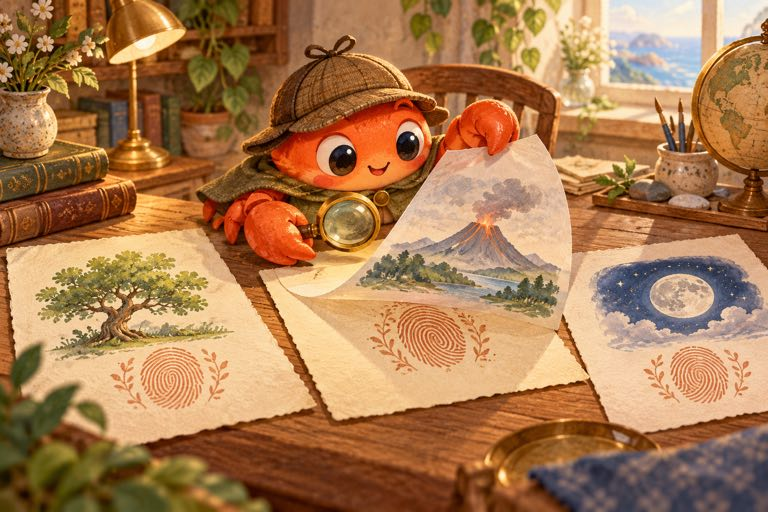

*A metaphor, not a literal disentanglement: topic and style can interact.*



*The identity is exact. The statistical benefit of either head must still be measured.*

<a id="instyle-groups"></a>

## 1. Finding the groups

The test passages come with no prompt ids, so every inferred group can be wrong. Branch A uses content-word TF-IDF cosine distance with average-linkage cut 0.85. Branch B averages content-word TF-IDF cosine distance and mean-centred GLM-4-9B layer-24 cosine distance, then cuts average linkage at 0.60. The branch-B stylegram also has its own median-normalised content distance, cut at 0.90.

Clusters of 2 to 18 passages are eligible for the corresponding group-dependent heads. Singletons retain their plain path. Groups larger than 18 are rejected by the code: they are incompatible with one shared prompt **if** that prompt has at most one passage from each of 18 authors. The training table supports that construction (2,699 filled cells out of 2,700 possible cells), but a cluster-size cutoff alone cannot prove any smaller cluster is pure or establish the hidden test's sampling protocol.


In [ ]:
# ============================================================ 1. grouping the test pool
def average_linkage_groups(D, thresh):
    """Cluster ids (1-based) from a square distance matrix, average linkage, cut at thresh."""
    if len(D) < 2:
        return np.ones(len(D), dtype=int)
    D = np.asarray(D, dtype=np.float64).copy()
    np.fill_diagonal(D, 0.0)
    return fcluster(linkage(squareform(D, checks=False), method='average'), thresh, criterion='distance')


def content_cosine_distance(texts, max_features=None):
    X = TfidfVectorizer(stop_words='english', sublinear_tf=True, max_features=max_features, dtype=np.float32).fit_transform(texts)
    return np.clip(1.0 - (X @ X.T).toarray(), 0.0, 1.0)


def mixed_groups(texts, E, thresh=GROUP_THRESH):
    """Average of the content-word TF-IDF cosine distance and the cosine distance of mean-centred, L2-normalised embeddings E."""
    if len(texts) < 2:
        return np.ones(len(texts), dtype=int)
    Z = np.asarray(E, dtype=np.float64)
    Z = Z - Z.mean(0)
    Z /= np.linalg.norm(Z, axis=1, keepdims=True) + 1e-12
    D = 0.5 * (content_cosine_distance(texts) + np.clip(1.0 - Z @ Z.T, 0.0, 2.0))
    return average_linkage_groups(D, thresh)


def normalised_content_groups(texts, thresh=STYLE_GROUP_THRESH):
    """The stylegram's grouping: content distance divided by its median off-diagonal value, cut at thresh."""
    if len(texts) < 2:
        return np.ones(len(texts), dtype=int)
    D = content_cosine_distance(texts, max_features=100_000)
    med = max(float(np.median(D[np.triu_indices(len(texts), 1)])), 1e-6)
    return average_linkage_groups(D / med, thresh)


def eligible(groups, lo=GROUP_MIN, hi=GROUP_MAX):
    size = np.bincount(groups)[groups]
    return (size >= lo) & (size <= hi)


def describe_groups(name, groups):
    size = np.bincount(groups)[groups]
    print(f'{name}: {len(groups)} rows | singletons {int((size == 1).sum())}  2-3: {int(((size >= 2) & (size <= 3)).sum())}'
          f'  4-18: {int(((size >= 4) & (size <= 18)).sum())}  >18: {int((size > 18).sum())}', flush=True)


G_TE, GROUP_ROWS = None, None   # branch B groups (content + GLM layer 24), set after the GLM pass (section 4)
G_A = average_linkage_groups(content_cosine_distance(TE), GROUP_A_THRESH) if len(TE) >= 2 else np.ones(len(TE), dtype=int)
ROWS_A = eligible(G_A)
describe_groups(f'branch A groups (content TF-IDF, cut {GROUP_A_THRESH})', G_A)

<a id="instyle-stylegrams"></a>

## 2. Style n-grams, extra passages, gates

Four TF-IDF views of each passage (character 3-5-grams, word 1-3-grams, *shape* n-grams where every word becomes `x` or `X`, and *function-word* n-grams where every content word becomes `CONTENT`) are stacked and fed to a LinearSVC. The public prompt-bank passages (one passage per prompt and label, prompts answered by at least 12 labels) join the training set; per class they share half of the class weight. A prompt-centred twin of the SVC is trained on prompt-centred training rows and replaces the plain SVC on inferred test groups.

Three optional kinds of *gate* are implemented after the blend and only re-rank inside a family; **these gates are off in the current configuration**: a within-Claude style SVC (original Claude rows plus the public Claude API passages), and within-GPT / within-Gemini / within-GLM SVCs trained on each family's rows plus its in-style extra passages. A passage predicted as GPT stays GPT; the gate only decides which GPT.

In [ ]:
# ============================================================ 2. style n-grams + extra passages + gates
FUNCTION_WORDS = frozenset("a an the and or but if while although because as so than that which who whom whose this these those it its "
                           "they them their theirs he him his she her hers we us our ours you your yours i me my mine in on at to from with "
                           "without for of by over under between through into about is are was were be been being have has had do does did "
                           "can could will would shall should may might must not no nor all any some each every both either neither other "
                           "another such only also just very too more most less least here there when where why how what whether then now "
                           "still yet even much many few little".split())
TOKEN_RE = re.compile(r"\w+|[^\w\s]")


def shape_view(text):
    return re.sub(r"[^\W\d_]+", lambda m: 'X' if m[0].isupper() else 'x', text)


def function_view(text):
    return ' '.join(t.lower() if (t.lower() in FUNCTION_WORDS or not t.isalnum()) else 'CONTENT' for t in TOKEN_RE.findall(text))


class StyleGrams:
    """Four stacked TF-IDF views: char 3-5, word 1-3, shape (char 2-6 of the x/X text), function-word (word 1-3 of the masked text)."""
    VIEWS = [('char', str, (3, 5), 250_000, 1.0), ('word', str, (1, 3), 180_000, 0.7),
             ('char', shape_view, (2, 6), 60_000, 0.5), ('word', function_view, (1, 3), 50_000, 0.5)]

    def fit(self, texts):
        self.vecs = []
        for analyzer, view, ngr, maxf, w in self.VIEWS:
            opts = dict(analyzer=analyzer, ngram_range=ngr, lowercase=False, sublinear_tf=True, min_df=2, max_features=maxf, dtype=np.float64)
            if analyzer == 'word':
                opts['token_pattern'] = r"(?u)\b\w+\b|[^\w\s]"
            self.vecs.append((TfidfVectorizer(**opts).fit([view(t) for t in texts]), view, w))
        return self

    def transform(self, texts):
        return hstack([v.transform([view(t) for t in texts]) * w for v, view, w in self.vecs], format='csr')


def sparse_group_centre(X, groups, lo=GROUP_MIN, hi=GROUP_MAX):
    """Subtract each group's mean row (sparse); groups outside [lo, hi] are left as they are."""
    X = csr_matrix(X)
    _, inv, cnt = np.unique(np.asarray(groups), return_inverse=True, return_counts=True)
    keep = np.flatnonzero((cnt >= lo) & (cnt <= hi))
    if not len(keep):
        return X.copy()
    col = np.full(len(cnt), -1); col[keep] = np.arange(len(keep))
    rows = np.flatnonzero(col[inv] >= 0)
    M = csr_matrix((np.ones(len(rows)), (rows, col[inv][rows])), shape=(X.shape[0], len(keep)))
    means = diags(1.0 / cnt[keep]) @ (M.T @ X)
    return (X - M @ means).tocsr()


def svc_probs(svc, X):
    return full_prob(softmax_rows(svc.decision_function(X)), svc.classes_)


# ---- public in-style passages (prompt-bank protocol), one per (prompt, label); prompts answered by >= EXTRA_MIN_LABELS labels
def load_extra_passages():
    sources = [('**/ntl_extra_passages_claude.csv', 'model', None), ('**/gen_passages.csv', 'model', None),
               ('**/ntl_generations.csv', 'label', 'finish_reason'), ('**/ntl_proxy_generations.csv', 'label', None),
               ('**/ntl_generated*.csv', 'model', 'finish'), ('**/passages_clean.csv', 'model', None)]
    parts = []
    for pattern, label_col, finish_col in sources:
        for f in sorted(glob.glob('/kaggle/input/' + pattern, recursive=True)):
            d = pd.read_csv(f)
            if finish_col and finish_col in d:
                d = d[d[finish_col].eq('stop')]
            d = d.rename(columns={label_col: 'model'})[['prompt_id', 'model', 'text']].copy()
            d['prompt_id'] = ('pv_' if f.endswith('passages_clean.csv') else '') + d['prompt_id'].astype(str)   # prvsiyan's prompts are a different bank
            parts.append(d)
    if not parts:
        return pd.DataFrame(columns=['prompt_id', 'model', 'text'])
    x = pd.concat(parts, ignore_index=True)
    x = x[x['model'].isin(LABELS)].copy()
    x['text'] = x['text'].astype(str).map(lambda t: re.sub(r'\s+', ' ', re.sub(r'^\*\*(.*)\*\*$', r'\1', t.strip())).strip())
    x = x[x['text'].str.split().str.len().between(30, 300)].drop_duplicates(subset=['model', 'text'])
    x = x.drop_duplicates(subset=['prompt_id', 'model'])
    x = x[x.groupby('prompt_id')['model'].transform('nunique') >= EXTRA_MIN_LABELS].reset_index(drop=True)
    return x


EXTRA = load_extra_passages()
EX_T, EX_Y, EX_G = EXTRA['text'].tolist(), EXTRA['model'].map(LAB2I).to_numpy(dtype=int), EXTRA['prompt_id'].to_numpy(dtype=object)
print(f'extra passages: {len(EXTRA)} rows, {EXTRA["prompt_id"].nunique()} prompts', flush=True)


def extra_sample_weights():
    """Per class: original rows keep (1 - EXTRA_SHARE) of the class weight, the class's extra rows share EXTRA_SHARE of it."""
    n_tr, n_ex = np.bincount(y, minlength=K).astype(float), np.bincount(EX_Y, minlength=K).astype(float)
    w_tr = np.where(n_ex[y] > 0, 1.0 - EXTRA_SHARE, 1.0)
    w_ex = EXTRA_SHARE * n_tr[EX_Y] / np.maximum(n_ex[EX_Y], 1.0)
    return np.concatenate([w_tr, w_ex])


_pf = sorted(glob.glob('/kaggle/input/**/pool_v4.parquet', recursive=True)) or (glob.glob(os.environ.get('NTL_POOL', '')) if SMOKE else [])
assert _pf, 'attach nishantdahal/ntl-handwriting-blend (pool_v4.parquet)'
POOL = pd.read_parquet(_pf[0])
POOL = POOL[POOL['model'].isin(LABELS) & ~POOL['text'].isin(set(TR))].reset_index(drop=True)
POOL_Y = POOL['model'].map(LAB2I).to_numpy(dtype=int)
print(f'public pool: {len(POOL)} rows, {POOL["prompt_id"].nunique()} prompts (from {_pf[0]})', flush=True)

# branch A member: the n-gram SVC on train + the whole pool, balanced class weights (the two-stage notebook's first member)
grams_pool = StyleGrams().fit(TR + POOL['text'].tolist())
svc_pool = LinearSVC(C=0.5, class_weight='balanced', random_state=42, max_iter=5000).fit(
    vstack([grams_pool.transform(TR), grams_pool.transform(POOL['text'].tolist())]).tocsr(), np.concatenate([y, POOL_Y]))
add_member('svc_pool', svc_probs(svc_pool, grams_pool.transform(TE)), weight=W_SVC_POOL, target=LOGIT_A)
del grams_pool, svc_pool

grams = StyleGrams().fit(TR + (POOL['text'].tolist() if STYLEGRAM_POOL else EX_T))   # vocabulary and idf from train + extra (or + pool)
X_tr, X_ex, X_te = grams.transform(TR), grams.transform(EX_T) if len(EX_T) else None, grams.transform(TE)


def fit_svc(X, labels, C=0.5, **kw):
    return LinearSVC(C=C, random_state=42, max_iter=4000).fit(X, labels, **kw)


if STYLEGRAM_POOL:   # train + pool, balanced class weights (the pool is unbalanced)
    svc_plain = LinearSVC(C=0.5, class_weight='balanced', random_state=42, max_iter=5000).fit(
        vstack([X_tr, grams.transform(POOL['text'].tolist())]).tocsr(), np.concatenate([y, POOL_Y]))
elif X_ex is not None:
    svc_plain = fit_svc(vstack([X_tr, X_ex]).tocsr(), np.concatenate([y, EX_Y]), sample_weight=extra_sample_weights())
else:
    svc_plain = fit_svc(X_tr, y)
P_style = svc_probs(svc_plain, X_te)

# centred twin: prompt-centred training rows (extra rows centred within their own prompts) -> inferred test groups
X_tr_c = sparse_group_centre(X_tr, PROMPT)
if X_ex is not None:
    svc_centred = fit_svc(vstack([X_tr_c, sparse_group_centre(X_ex, EX_G, GROUP_MIN, 10 ** 6)]).tocsr(), np.concatenate([y, EX_Y]),
                          sample_weight=extra_sample_weights())
else:
    svc_centred = fit_svc(X_tr_c, y)
G_style = normalised_content_groups(TE)
rows_style = eligible(G_style)
describe_groups('stylegram groups', G_style)
if rows_style.any():
    P_style[rows_style] = svc_probs(svc_centred, sparse_group_centre(X_te[rows_style], G_style[rows_style]))
if TINY:   # exercise the centred path on training rows grouped by their true prompt (output discarded)
    st_idx, st_g = self_test_rows()
    acc = np.mean(svc_centred.classes_[svc_centred.decision_function(sparse_group_centre(X_tr[st_idx], st_g)).argmax(1)] == y[st_idx])
    print(f'  centred stylegram self-test on {len(st_idx)} training rows (seen in training): acc {acc:.2f}', flush=True)
add_member('stylegram', P_style)
del X_tr_c, svc_plain, svc_centred, P_style


# ---- gates: style SVCs that only re-rank inside one family after the blend
def family_gate(texts, labels, classes, C, sample_weight=None, balanced=False):
    g = StyleGrams().fit(texts)
    svc = LinearSVC(C=C, class_weight='balanced' if balanced else None, random_state=42, max_iter=4000).fit(
        g.transform(texts), labels, sample_weight=sample_weight)
    assert list(svc.classes_) == list(classes)
    d = svc.decision_function(g.transform(TE))
    return np.column_stack([-d, d]) if len(classes) == 2 else d


GATES = {}
api_claude = sorted(glob.glob('/kaggle/input/**/ntl_extra_passages_claude.csv', recursive=True)) if GATES_ON else []
if api_claude:
    api = pd.read_csv(api_claude[0])
    m = np.isin(y, FAMILY_IDX['claude'])
    GATES['claude'] = family_gate([t for t, k in zip(TR, m) if k] + api['text'].astype(str).tolist(),
                                  np.concatenate([y[m], api['model'].map(LAB2I).to_numpy(dtype=int)]), FAMILY_IDX['claude'], 0.5)
    print(f'claude gate: {int(m.sum())} official + {len(api)} API rows', flush=True)
    del api
else:
    print('Claude gate off', flush=True)
for fam, C in ([('gpt', 1.0), ('gemini', 1.0), ('glm', 0.5)] if GATES_ON else []):
    m, me = np.isin(y, FAMILY_IDX[fam]), np.isin(EX_Y, FAMILY_IDX[fam])
    GATES[fam] = family_gate([t for t, k in zip(TR, m) if k] + [t for t, k in zip(EX_T, me) if k], np.concatenate([y[m], EX_Y[me]]),
                             FAMILY_IDX[fam], C, sample_weight=np.concatenate([np.ones(int(m.sum())), np.full(int(me.sum()), 0.25)]), balanced=True)
    print(f'{fam} gate: {int(m.sum())} official + {int(me.sum())} extra rows', flush=True)
del grams, X_tr, X_ex, X_te

<a id="instyle-stylometry"></a>

## 3. Stylometry

The current code creates **361 features** in the validated environment: 20 handcrafted statistics, 23 punctuation rates, and 318 English-stop-word frequencies. The handcrafted part describes sentence and word lengths, type-token ratio, capitals, digits, non-ASCII characters, selected endings and a few connective/sentence-start patterns. A 400-tree LightGBM classifier reads this vector. These are measurements of the observed passage, not proof that a model has an intrinsic or route-invariant fingerprint.


In [ ]:
# ============================================================ 3. stylometric features + LightGBM
PUNCT = list(',.;:!?()[]"\'-') + ['—', '–', '‘', '’', '“', '”', '…', '*', '/', '%']
STOPS = sorted(ENGLISH_STOP_WORDS)
SENT_RE, WORD_RE = re.compile(r'(?<=[.!?])\s+'), re.compile(r"[A-Za-z’']+")


def stylometry(t):
    words = WORD_RE.findall(t)
    low = [w.lower() for w in words]
    nw, nc = max(len(words), 1), max(len(t), 1)
    sents = [s for s in SENT_RE.split(t.strip()) if s]
    sl = np.array([len(WORD_RE.findall(s)) for s in sents] or [0], dtype=float)
    wl = np.array([len(w) for w in words] or [0], dtype=float)
    f = [np.log1p(nw), len(sents), sl.mean(), sl.std(), sl.max(), sl.min(), wl.mean(), wl.std(), (wl >= 9).mean(), len(set(low)) / nw,
         sum(c.isupper() for c in t) / nc, sum(c.isdigit() for c in t) / nc, sum(ord(c) > 127 for c in t) / nc,
         t.count(', ') / nw, t.count(' and ') / nw, t.count(' but ') / nw,
         sum(1 for s in sents if s[:1].isupper() and s.split()[0].lower() in ('this', 'these', 'it', 'they')) / max(len(sents), 1),
         sum(w.endswith('ly') for w in words) / nw, sum(w.endswith('ing') for w in words) / nw, sum(w.endswith('tion') for w in words) / nw]
    f += [t.count(q) / nw for q in PUNCT]
    counts = pd.Series(low).value_counts() if low else pd.Series(dtype=float)
    f += [counts.get(s, 0) / nw for s in STOPS]
    return f


F_tr, F_te = (np.array([stylometry(t) for t in txt], dtype=np.float32) for txt in (TR, TE))
try:
    import lightgbm as lgb
    booster = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=10, subsample=0.8, subsample_freq=1,
                                 colsample_bytree=0.5, reg_lambda=1.0, random_state=0, verbose=-1, n_jobs=4).fit(F_tr, y)
    add_member('stylometry_lgb', full_prob(booster.predict_proba(F_te), booster.classes_))
    del booster
except ImportError:
    assert SMOKE, 'lightgbm missing'
    print('smoke: lightgbm unavailable, stylometry member skipped', flush=True)
del F_tr, F_te

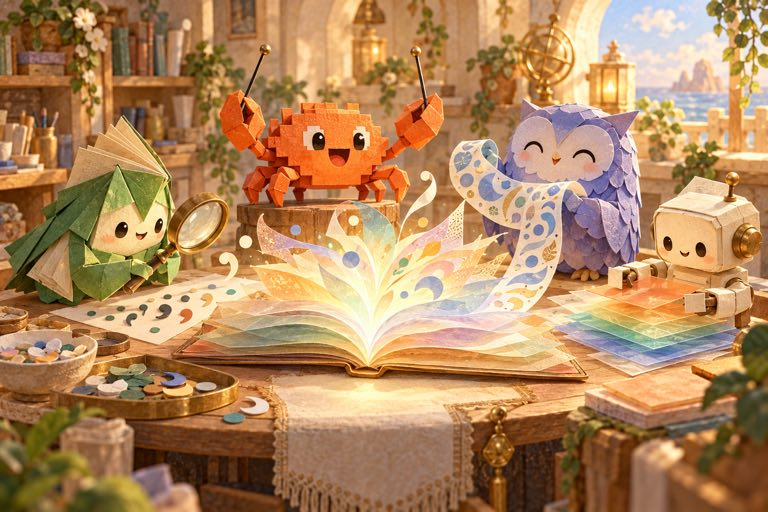

*Diversity is useful only when a member contributes held-out evidence beyond the rest of the ensemble.*

<a id="instyle-frozen"></a>

## 4. Frozen models, centred twins, and the Gaussian group heads

Version 5 also read the mean states of the **first three layers** of Qwen3-4B-Base here (Joseph Adamski's early-layer member, mixed at 10% into branch A, with test-side standardisation and its own Gaussian head). The complete notebook scored 0.603 against version 4's 0.604, so from version 6 that member is switched off (`EARLY_ON = False`) and those layers are no longer pooled. The ATLAS adapter of the same notebook is not used either: it needs a third-party inference package run per class and passage.

Every frozen model is truncated to the deepest layer it needs. Decoders run in fp16 (with a bf16 retry if a batch overflows), encoders in fp32. Pooling is a masked mean over all tokens, or over *style tokens* only (stop words and punctuation) for the Qwen3-4B and two encoder views.

Each plain head is a StandardScaler + LogisticRegression; at test time the features are standardised with the **test** mean and standard deviation (a label-free transductive step). On grouped test rows a centred twin, trained on prompt-centred training features, adds its evidence on top. Note that in the 0.563 blend the four decoder plain heads carry weight 0: their original nonzero contributions are through the centred twins. The separately weighted Gaussian heads also contribute in this notebook.

The next cell is the Gaussian group head, copied from our research tool. The cell after it extracts the features and fits plain head, centred twin and Gaussian head per view.

In [ ]:
# ============================================================ 4b. shared-prompt Gaussian group head
# Verbatim core of our research tool tools/group_gaussian.py (sha256 8a42427b77a37f56...), numpy only.
# Model per dense view, in a reduced space z (standardise -> within-prompt-residual PCA, fitted on training rows):
#   z_i = mu_{y_i} + p_g + e_i,  p_g ~ N(0, S_p) shared by every passage of prompt group g,  e_i ~ N(0, S_e).
# A joint diagonalisation makes the dimensions independent; for a detected group of n passages the exact joint
# log-likelihood of a label tuple is sum_i a_i(c_i) + sum_{i<j} b_ij(c_i, c_j). Groups of 2-3 are decoded exactly over
# all label tuples with the at-most-once constraint; larger groups by a cavity EM with the finite-population-corrected
# prompt-effect estimate lam / (1 + (n-1) lam); singletons integrate the prompt effect out (never used here).
import itertools
K = 18
DEFAULT = {"red": "wpca", "d": 256, "se_shrink": "lw", "sp_shrink": "lw", "lam_floor": 1e-4, "n_exact": 3, "inj": True,
           "iters": 5, "repel": True, "sp_scale": 1.0}

# =================================================================== primitives ====
def _lse(A, axis=None, keepdims=False):
    m = np.max(A, axis=axis, keepdims=True); m = np.where(np.isfinite(m), m, 0.0)
    out = np.log(np.sum(np.exp(A - m), axis=axis, keepdims=True)) + m
    if keepdims: return out
    return np.squeeze(out, axis=axis) if axis is not None else float(out.item())

def log_softmax(L): return L - _lse(L, axis=1, keepdims=True)

def _lw_shrinkage(X):
    """Ledoit-Wolf shrinkage coefficient for rows X that are already centred (sklearn formula, assume_centered)."""
    from sklearn.covariance import ledoit_wolf_shrinkage
    return float(ledoit_wolf_shrinkage(X, assume_centered=True))

def _shrunk(S, a):
    d = S.shape[0]; return (1 - a) * S + a * (np.trace(S) / d) * np.eye(d)

def _two_way(Z, y, pinv, G, iters=4):
    """additive fit Z = mu[y] + P[prompt] + E by alternating means (balanced design -> converges in 1-2 rounds)."""
    P = np.zeros((G, Z.shape[1])); cnt_p = np.bincount(pinv, minlength=G).astype(float)
    cls = np.unique(y); mu = np.zeros((K, Z.shape[1]))
    for _ in range(iters):
        R = Z - P[pinv]
        for c in cls: mu[c] = R[y == c].mean(0)
        R = Z - mu[y]; P = np.zeros_like(P); np.add.at(P, pinv, R); P /= cnt_p[:, None]
    return mu, P, cnt_p

def fit(X, y, prompts, cfg=None):
    """fit the shared-prompt Gaussian on training rows. X (N, D) raw features, y (N,) labels in 0..17, prompts (N,) group ids.
    Returns a params dict (numpy arrays + floats); temperatures default to 1 (set by the caller's cross-fit)."""
    c = dict(DEFAULT); c.update(cfg or {})
    X = np.asarray(X, dtype=np.float64); y = np.asarray(y); N, D = X.shape
    pu, pinv = np.unique(np.asarray(prompts), return_inverse=True); G = len(pu)
    mx = X.mean(0); sx = X.std(0); sx = np.where(sx > 1e-8, sx, 1.0); Xs = (X - mx) / sx
    if c["red"] == "none":
        V = np.eye(D)
    else:
        if c["red"] == "wpca":
            Pm = np.zeros((G, D)); np.add.at(Pm, pinv, Xs); Pm /= np.bincount(pinv)[:, None]; R = Xs - Pm[pinv]
        elif c["red"] == "pca": R = Xs
        else: raise ValueError(c["red"])
        d = int(min(c["d"], N - G - 1, D))
        # economy SVD through the (N x N) Gram matrix (N << D for the real views)
        if N < D:
            w, U = np.linalg.eigh(R @ R.T); o = np.argsort(w)[::-1][:d]; w, U = np.clip(w[o], 1e-12, None), U[:, o]
            V = (R.T @ U) / np.sqrt(w)
        else:
            _, _, Vt = np.linalg.svd(R, full_matrices=False); V = Vt[:d].T
    Z = Xs @ V; d = Z.shape[1]
    mu, P, ng = _two_way(Z, y, pinv, G)
    E = Z - mu[y] - P[pinv]; dof = max(N - G - len(np.unique(y)) + 1, 1)
    Se_raw = E.T @ E / dof
    ae = _lw_shrinkage(E) if c["se_shrink"] == "lw" else float(c["se_shrink"]); Se = _shrunk(Se_raw, ae)
    Pc = P - P.mean(0); Sp_raw = Pc.T @ Pc / max(G - 1, 1) - np.mean(1.0 / ng) * Se_raw
    ap = _lw_shrinkage(Pc) if c["sp_shrink"] == "lw" else float(c["sp_shrink"])
    tr = max(np.trace(Sp_raw), 1e-8 * np.trace(Se)); Sp = (1 - ap) * Sp_raw + ap * (tr / d) * np.eye(d); Sp *= c["sp_scale"]
    # joint diagonalisation: A Se A' = I, A Sp A' = diag(lam)
    L = np.linalg.cholesky(Se); Li = np.linalg.inv(L); M = Li @ Sp @ Li.T; M = 0.5 * (M + M.T)
    lam, Q = np.linalg.eigh(M); lam = np.clip(lam, c["lam_floor"], None); A = Q.T @ Li
    W = V @ A.T
    return {"mx": mx, "sx": sx, "W": W, "m": mu @ A.T, "lam": lam, "T1": 1.0, "Tg": 1.0,
            "info": {"d": int(d), "a_e": round(ae, 4), "a_p": round(ap, 4), "lam_pct": np.round(np.percentile(lam, [5, 50, 95, 100]), 3).tolist()}, "cfg": c}

def transform(X, prm): return ((np.asarray(X, dtype=np.float64) - prm["mx"]) / prm["sx"]) @ prm["W"]

_MASK = {}
def _inj_mask(n, C):
    if (n, C) not in _MASK:
        grids = np.meshgrid(*[np.arange(C)] * n, indexing="ij"); bad = np.zeros([C] * n, bool)
        for i, j in itertools.combinations(range(n), 2): bad |= grids[i] == grids[j]
        _MASK[(n, C)] = bad
    return _MASK[(n, C)]

def singleton_ll(U, m, lam):
    """(n, C) log N(u; m_c, I + diag lam) up to a constant (p integrated out)."""
    R = U[:, None, :] - m[None]; return -0.5 * (R ** 2 / (1 + lam)).sum(-1)

def joint_terms(U, m, lam):
    """a (n, C) and B (n, n, C, C) of the exact joint log-likelihood of one group (constant in c dropped)."""
    n = len(U); gam = lam / (1 + n * lam); R = U[:, None, :] - m[None]
    a = -0.5 * (R ** 2 * (1 - gam)).sum(-1); G = R * np.sqrt(gam); B = np.einsum("icd,jed->ijce", G, G)
    return a, B

def joint_table(a, B):
    """full tuple table Q[c_1, ..., c_n] = sum_i a_i + sum_{i<j} B_ij."""
    n, C = a.shape; Q = np.zeros([C] * n)
    for i in range(n):
        sh = [1] * n; sh[i] = C; Q = Q + a[i].reshape(sh)
    for i, j in itertools.combinations(range(n), 2):
        sh = [1] * n; sh[i] = C; sh[j] = C; Q = Q + B[i, j].reshape(sh)
    return Q

def exact_marginals(Q, T=1.0, inj=True):
    """per-passage log marginal posteriors (n, C) from a tuple table Q (unnormalised log joint), tempered by 1/T."""
    n = Q.ndim; C = Q.shape[0]; Qt = Q / T
    if inj and n >= 2: Qt = np.where(_inj_mask(n, C), -np.inf, Qt)
    lz = _lse(Qt); out = np.empty((n, C))
    for i in range(n):
        ax = tuple(k for k in range(n) if k != i); out[i] = (_lse(Qt, axis=ax) if ax else Qt) - lz
    return out

def em_marginals(U, m, lam, T=1.0, iters=5, repel=False, q0=None):
    """cavity EM for one group (any n >= 2): returns (n, C) log q."""
    n = len(U); v = lam / (1 + (n - 1) * lam)
    L = singleton_ll(U, m, lam) / T if q0 is None else np.log(np.clip(q0, 1e-300, None))
    q = np.exp(log_softmax(L))
    for _ in range(iters):
        s = U - q @ m; S = s.sum(0); Pm = (S[None] - s) * v                  # cavity prompt-effect means (n, d)
        R = U[:, None, :] - Pm[:, None, :] - m[None]; L = -0.5 * (R ** 2 / (1 + v)).sum(-1) / T
        if repel:   # mean-field at-most-once: discourage classes the other members already hold
            lo = np.log(np.clip(1 - q, 1e-6, None)); L = L + (lo.sum(0)[None] - lo)
        q = np.exp(log_softmax(L))
    return log_softmax(L)

LAM_DIFF = 1e6
def lam_g(prm, cfg=None):
    """lam used for groups: the fitted one, or ~infinity in the paired-difference ablation (cfg 'diff'): then the joint likelihood
    only sees within-group differences (x_i - x_j around mu_a - mu_b with covariance 2 S_e; triples: centred observations vs
    centred prototypes) and the prompt term cancels exactly."""
    c = dict(prm.get("cfg", DEFAULT)); c.update(cfg or {})
    return np.full_like(prm["lam"], LAM_DIFF) if c.get("diff") else prm["lam"]

def group_logpost(U, prm, T1=None, Tg=None, cfg=None):
    c = dict(prm.get("cfg", DEFAULT)); c.update(cfg or {}); n = len(U); lg = lam_g(prm, cfg)
    T1 = prm["T1"] if T1 is None else T1; Tg = prm["Tg"] if Tg is None else Tg
    if n == 1: return log_softmax(singleton_ll(U, prm["m"], prm["lam"]) / T1)
    if n <= c["n_exact"]:
        a, B = joint_terms(U, prm["m"], lg); return exact_marginals(joint_table(a, B), Tg, c["inj"])
    return em_marginals(U, prm["m"], lg, Tg, c["iters"], c["repel"])

def scores(X_pool, lab, prm, T1=None, Tg=None, cfg=None, U=None):
    """(n, 18) log-probabilities for every pool row; lab = detected group labels of the pool rows (singletons allowed)."""
    U = transform(X_pool, prm) if U is None else U; lab = np.asarray(lab); n = len(U); out = np.empty((n, prm["m"].shape[0]))
    sizes = np.bincount(lab); s1 = sizes[lab] == 1
    T1 = prm["T1"] if T1 is None else T1
    if s1.any(): out[s1] = log_softmax(singleton_ll(U[s1], prm["m"], prm["lam"]) / T1)
    for g in np.where(sizes >= 2)[0]:
        ii = np.where(lab == g)[0]; out[ii] = group_logpost(U[ii], prm, T1, Tg, cfg)
    return out

def coupling_tables(U, lab, prm, nmax=3):
    """pure version of GaussBranch.coupling for the notebook: {group label: (row positions, Psi)} for detected groups of size 2..nmax,
    Psi(c) = [sum_i (a_i^(n)(c_i) - a1_i(c_i)) + sum_{i<j} b_ij(c_i, c_j)] / T_g = the joint log-likelihood beyond the independent singletons."""
    lab = np.asarray(lab); sizes = np.bincount(lab); out = {}; lg = lam_g(prm)
    for gl in np.where((sizes >= 2) & (sizes <= nmax))[0]:
        ii = np.where(lab == gl)[0]; a, B = joint_terms(U[ii], prm["m"], lg)
        out[int(gl)] = (ii, joint_table(a - singleton_ll(U[ii], prm["m"], lg), B) / prm["Tg"])
    return out


def crf_scores(unary, couplings, n_rows, t, beta):
    """log marginals (n_rows, 18) of q(c) ~ exp(sum_i unary_i(c_i) / t + beta * sum_v Psi_v(c)) under at-most-once, for every group in
    couplings (list over views of {gl: (positions, Psi)}); rows outside those groups get unary / t."""
    out = log_softmax(unary / t)
    if not couplings: return out
    for gl, (ii, _) in couplings[0].items():
        Q = joint_table(unary[ii] / t, np.zeros((len(ii), len(ii), K, K)))
        for cv in couplings: Q = Q + beta * cv[gl][1]
        out[ii] = exact_marginals(Q, 1.0, True)
    return out

In [ ]:
# ============================================================ 4. frozen models: plain heads, centred twins, Gaussian group heads
if not SMOKE:
    from transformers import AutoConfig, AutoModel, AutoTokenizer
CACHED_PARTS = {}   # key -> {part name: (train features, test features)}


def find_checkpoint(model_type, hidden=None, dir_name=None):
    """A checkpoint directory under /kaggle/input by model_type (+ hidden size) or by directory name."""
    pattern = f'/kaggle/input/**/{dir_name}/config.json' if dir_name else '/kaggle/input/**/config.json'
    for cfg in sorted(glob.glob(pattern, recursive=True)):
        try:
            c = json.load(open(cfg))
        except Exception:
            continue
        if dir_name or (c.get('model_type') == model_type and (hidden is None or c.get('hidden_size') == hidden)):
            return os.path.dirname(cfg)
    return None


def localise(path, keep_layers=None):
    """Copy a checkpoint from the slow dataset mount to local disk before loading (sequential copy beats the mount's random reads by an
    order of magnitude). With keep_layers, only the safetensors shards holding embeddings, the final norm and layers < keep_layers are copied."""
    if not path.startswith('/kaggle/input'):
        return path
    dst = '/tmp/localised/' + path.strip('/').replace('/', '__')
    if os.path.exists(os.path.join(dst, 'config.json')):
        return dst
    os.makedirs(dst, exist_ok=True)
    t = time.time()
    names = sorted(os.listdir(path))
    idx = os.path.join(path, 'model.safetensors.index.json')
    skip = set()
    if keep_layers is not None and os.path.exists(idx):
        wm = json.load(open(idx))['weight_map']
        needed = {sh for k, sh in wm.items() if not re.search(r'\.layers\.(\d+)\.', k) or int(re.search(r'\.layers\.(\d+)\.', k).group(1)) < keep_layers}
        skip = {sh for sh in set(wm.values()) if sh not in needed}
    copied = 0
    for n in names:
        src = os.path.join(path, n)
        if os.path.isdir(src) or n in skip:
            continue
        shutil.copyfile(src, os.path.join(dst, n))
        copied += os.path.getsize(src)
    print(f'  localised {os.path.basename(path)}: {copied / 2**30:.1f} GiB in {time.time() - t:.0f}s' + (f' ({len(skip)} shards skipped)' if skip else ''), flush=True)
    return dst


def load_truncated_decoder(path, keep, dtype):
    cfg = AutoConfig.from_pretrained(path)
    cfg.num_hidden_layers = keep
    if getattr(cfg, 'layer_types', None):
        cfg.layer_types = cfg.layer_types[:keep]
    kw = dict(config=cfg, dtype=dtype)
    if DEV == 'cuda':
        kw['device_map'] = 'auto'
    return AutoModel.from_pretrained(path, **kw).eval()


def style_token_mask(tok):
    """Vocabulary mask of 'style' tokens: the decoded piece is an English stop word or pure punctuation."""
    pieces = [tok.decode([i]) for i in range(len(tok))]
    return torch.tensor([(p.strip().lower() in ENGLISH_STOP_WORDS) or bool(re.fullmatch(r'\s*[^\w\s]+\s*', p)) for p in pieces])


@torch.no_grad()
def pooled_states(model, tok, texts, parts, decoder, bs, max_len=512):
    """{'L{layer}_{pool}': (n, hidden)} masked mean pools of hidden_states[layer] (all tokens, or style tokens only)."""
    H = model.config.hidden_size
    out = {f'L{L}_{pool}': np.zeros((len(texts), H), dtype=np.float32) for L, pool in parts}
    smask = style_token_mask(tok) if any(pool == 'style' for _, pool in parts) else None
    dev = next(model.parameters()).device
    order = np.argsort([len(t) for t in texts])
    retried = 0
    for b0 in range(0, len(texts), bs):
        idx = order[b0:b0 + bs]
        if decoder:
            batch = [(tok.bos_token or '') + texts[i] for i in idx]
            enc = tok(batch, return_tensors='pt', padding=True, truncation=True, max_length=max_len, add_special_tokens=False).to(dev)
        else:
            enc = tok([texts[i] for i in idx], return_tensors='pt', padding=True, truncation=True, max_length=max_len).to(dev)
        hs = model(**enc, output_hidden_states=True).hidden_states
        if decoder and not all(torch.isfinite(hs[L]).all() for L, _ in parts):   # fp16 overflow: redo the batch in bf16
            retried += 1
            model.to(torch.bfloat16)
            hs = model(**enc, output_hidden_states=True).hidden_states
        m_all = enc['attention_mask'].float()
        for L, pool in parts:
            m = m_all * smask.to(m_all.device)[enc['input_ids']].float() if pool == 'style' else m_all
            m = m.unsqueeze(-1).to(hs[L].device)
            out[f'L{L}_{pool}'][idx] = ((hs[L].float() * m).sum(1) / m.sum(1).clamp(min=1)).cpu().numpy()
        del hs, enc
    if retried:
        print(f'  {retried} batches redone in bf16', flush=True)
    return {k: np.nan_to_num(v) for k, v in out.items()}


def pseudo_parts(parts, dim=48):
    """SMOKE only: deterministic stand-ins for the model passes (TF-IDF SVD of the texts), same downstream code."""
    from sklearn.decomposition import TruncatedSVD
    tf = TfidfVectorizer(analyzer='char', ngram_range=(2, 4), sublinear_tf=True, min_df=2).fit(TR + TE)
    out = {}
    for j, (L, pool) in enumerate(parts):
        svd = TruncatedSVD(dim, random_state=L + 7 * j).fit(tf.transform(TR))
        out[f'L{L}_{pool}'] = (svd.transform(tf.transform(TR)).astype(np.float32), svd.transform(tf.transform(TE)).astype(np.float32))
    return out


def extract_parts(key, parts, loader):
    """Train and test pools for every requested part; loader() returns (model, tok, decoder flag, batch size)."""
    if SMOKE:
        return pseudo_parts(parts)
    model, tok, decoder, bs = loader()
    tr, te = pooled_states(model, tok, TR, parts, decoder, bs), pooled_states(model, tok, TE, parts, decoder, bs)
    del model, tok
    gc.collect()
    if DEV == 'cuda':
        torch.cuda.empty_cache()
    return {k: (tr[k], te[k]) for k in tr}


def decoder_loader(model_type, hidden, keep):
    def load():
        path = find_checkpoint(model_type, hidden)
        assert path, f'no {model_type} checkpoint with hidden size {hidden} under /kaggle/input'
        if '/models/' not in path:   # a dataset mount (the GLM checkpoint): copy the shards of the first `keep` layers to local disk first
            path = localise(path, keep_layers=keep)
        tok = AutoTokenizer.from_pretrained(path)
        tok.padding_side = 'right'
        if tok.pad_token is None:
            tok.pad_token = tok.eos_token
        return load_truncated_decoder(path, keep, torch.float16 if DEV == 'cuda' else torch.float32), tok, True, 8
    return load


def encoder_loader(dir_name):
    def load():
        path = find_checkpoint(None, dir_name=dir_name)
        assert path, f'encoder directory {dir_name} not found under /kaggle/input'
        path = localise(path)
        return AutoModel.from_pretrained(path, dtype=torch.float32).to(DEV).eval(), AutoTokenizer.from_pretrained(path), False, 16
    return load


def concat_parts(cache, parts):
    return (np.concatenate([cache[f'L{L}_{p}'][0] for L, p in parts], 1), np.concatenate([cache[f'L{L}_{p}'][1] for L, p in parts], 1))


def plain_and_twin(key, Etr, Ete, C):
    """Plain head (test-side standardisation) for the blend; centred twin evidence on grouped rows."""
    if W[key] > 0:
        sc = StandardScaler().fit(Etr)
        clf = LogisticRegression(C=C, max_iter=5000).fit(sc.transform(Etr), y)
        Xte = (Ete - Ete.mean(0)) / (Ete.std(0) + 1e-6) if len(Ete) >= 2 else sc.transform(Ete)
        add_member(key, full_prob(clf.predict_proba(Xte), clf.classes_))
    else:
        print(f'  {key}: plain head has weight 0 in the 0.563 blend, not fitted', flush=True)
    if key in TWIN_W:
        csc = StandardScaler().fit(group_centre_dense(Etr, PROMPT))
        twin = LogisticRegression(C=C, max_iter=5000).fit(csc.transform(group_centre_dense(Etr, PROMPT)), y)
        if GROUP_ROWS.any():
            pc = twin.predict_proba(csc.transform(group_centre_dense(Ete[GROUP_ROWS], G_TE[GROUP_ROWS])))
            add_member(key + '_twin', full_prob(pc, twin.classes_), rows=GROUP_ROWS, weight=TWIN_W[key])
        if TINY:
            st_idx, st_g = self_test_rows()
            ps = twin.predict_proba(csc.transform(group_centre_dense(Etr[st_idx], st_g)))
            print(f'  {key} twin self-test on {len(st_idx)} training rows (seen in training): acc {np.mean(twin.classes_[ps.argmax(1)] == y[st_idx]):.2f}', flush=True)


def gaussian_group_head(name, spec, Xtr, Xte):
    """Our addition: fit the shared-prompt Gaussian on the training prompts, score the grouped test rows jointly within their group."""
    prm = fit(Xtr, y, PROMPT, dict(GAUSS_SETTING, d=spec['d']))
    prm['T1'], prm['Tg'] = spec['T1'], spec['Tg']
    print(f'  {name}: d {prm["info"]["d"]}, shrinkage e/p {prm["info"]["a_e"]}/{prm["info"]["a_p"]}, lam pct {prm["info"]["lam_pct"]}', flush=True)
    if GROUP_ROWS.any():
        LP = scores(Xte[GROUP_ROWS], np.unique(G_TE[GROUP_ROWS], return_inverse=True)[1], prm)
        add_member(name, np.exp(LP), rows=GROUP_ROWS, weight=spec['w'])
    if TINY:
        st_idx, st_g = self_test_rows()
        LP = scores(Xtr[st_idx], st_g, prm)
        print(f'  {name} self-test on {len(st_idx)} training rows (seen in training): acc {np.mean(LP.argmax(1) == y[st_idx]):.2f}', flush=True)


def lm_member(key, model_type, hidden, parts, extra_parts, C):
    global G_TE, GROUP_ROWS
    print(f'[{key}] {model_type} hidden {hidden} parts {parts + extra_parts}', flush=True)
    cache = extract_parts(key, parts + extra_parts, decoder_loader(model_type, hidden, max(L for L, _ in parts + extra_parts) + 1))
    if G_TE is None:   # the GLM pass comes first: its layer-24 pool defines the test groups
        G_TE = mixed_groups(TE, cache[f'L{GROUP_LAYER}_mean'][1])
        GROUP_ROWS = eligible(G_TE)
        describe_groups('test groups (content + GLM L24)', G_TE)
        if SMOKE:
            same_g, same_p = G_TE[:, None] == G_TE[None, :], test['prompt_id'].to_numpy(dtype=object)[:, None] == test['prompt_id'].to_numpy(dtype=object)[None, :]
            off = ~np.eye(len(TE), dtype=bool)
            print(f'  smoke grouping: pair precision {(same_g & same_p & off).sum() / max((same_g & off).sum(), 1):.2f} '
                  f'recall {(same_g & same_p & off).sum() / max((same_p & off).sum(), 1):.2f}', flush=True)
    CACHED_PARTS[key] = cache
    plain_and_twin(key, *concat_parts(cache, parts), C)
    for name, spec in GAUSS_HEADS.items():
        if spec['src'] == key:
            gaussian_group_head(name, spec, *cache[spec['part']])
    global P_EARLY
    if key == 'q3_4b' and EARLY['mix'] > 0:   # version 5: the early-layer classifier (mean states of layers 1-3) -> probabilities mixed into branch A, + its Gaussian head
        Etr, Ete = concat_parts(cache, [(L, 'mean') for L in EARLY['layers']])
        sc = StandardScaler().fit(Etr)
        clf = LogisticRegression(C=EARLY['C'], max_iter=1200).fit(sc.transform(Etr), y)
        Xte = (Ete - Ete.mean(0)) / (Ete.std(0) + 1e-6) if len(Ete) >= 50 else sc.transform(Ete)   # test-side standardisation on a real test pool
        P_EARLY = full_prob(clf.predict_proba(Xte), clf.classes_)
        print(f'  early-layer classifier (Qwen3-4B L{EARLY["layers"]}): mixed into branch A at {EARLY["mix"]}', flush=True)
        prm = fit(Etr, y, PROMPT, dict(GAUSS_SETTING, d=EARLY['gauss_d']))
        prm['T1'] = prm['Tg'] = EARLY['gauss_T']
        if ROWS_A.any():
            LP = scores(Ete[ROWS_A], np.unique(G_A[ROWS_A], return_inverse=True)[1], prm)
            add_member('gauss_early', np.exp(LP), rows=ROWS_A, weight=EARLY['gauss_w'], target=LOGIT_A)
        if TINY:
            st_idx, st_g = self_test_rows()
            print(f'  gauss_early self-test on {len(st_idx)} training rows (seen in training): acc {np.mean(scores(Etr[st_idx], st_g, prm).argmax(1) == y[st_idx]):.2f}', flush=True)
        del Etr, Ete
    del cache
    CACHED_PARTS.pop(key)
    gc.collect()


def enc_member(key, dir_name, parts, C):
    print(f'[{key}] {dir_name} parts {parts}', flush=True)
    cache = extract_parts(key, parts, encoder_loader(dir_name))
    plain_and_twin(key, *concat_parts(cache, parts), C)
    for name, spec in GAUSS_HEADS.items():
        if spec['src'] == key:
            gaussian_group_head(name, spec, *cache[spec['part']])
    del cache
    gc.collect()


P_EARLY = None
for key, model_type, hidden, parts, extra_parts, C in LM_HEADS:
    if key == 'glm9b':   # the groups come from this pass: not optional
        lm_member(key, model_type, hidden, parts, extra_parts, C)
    else:
        guard(key, lm_member, key, model_type, hidden, parts, extra_parts, C)
if G_TE is None:   # no GLM pass (smoke without models): content-only groups for branch B too
    G_TE, GROUP_ROWS = G_A.copy(), ROWS_A.copy()
for key, dir_name, parts, C in ENC_HEADS:
    guard(key, enc_member, key, dir_name, parts, C)

<a id="instyle-loras"></a>

## 5. LoRA classifiers

The five branch-B LoRA classifiers (four Qwen3-8B variants and one Qwen2.5-7B variant) share one recipe: a decoder trunk truncated to 24 (Qwen3-8B-Base) or 20 (Qwen2.5-7B) layers with a LoRA adapter on every linear layer, the masked mean of eight pooled layers each through its own LayerNorm, concatenated, and a linear readout. The checkpoints are public kernel outputs; here they are inference only. The training kernel of the public LoRA24 became private on 23 October 2026, so that member is skipped when its output is not attached (the loader prints a warning and the blend goes on without it). Where a checkpoint ships reference features for the first three training passages, the code compares its forward pass against those anchors and requires mean relative error below 0.02. That guard is conditional on the anchor file existing; it is a parity check, not held-out accuracy. Two of the checkpoints also provide a centred readout, used as a twin on grouped rows, and one provides a within-Claude head used by the Claude gate.

In [ ]:
# ============================================================ 5. LoRA classifiers (inference only)
@torch.no_grad()
def score_lora_checkpoints(trunk_spec, pool_layers, checkpoints):
    """One truncated trunk, adapters swapped in turn. Plain readout -> blend member; centred readout -> twin on grouped rows;
    within-Claude readout -> Claude gate."""
    import importlib.util as iu
    _find = iu.find_spec   # Kaggle's torchao build is rejected by peft; hide it (unused here)
    iu.find_spec = lambda name, *a, **k: None if name.split('.')[0] == 'torchao' else _find(name, *a, **k)
    from peft import PeftModel
    import peft.import_utils as pi
    pi.is_torchao_available = lambda *a, **k: False
    from safetensors.torch import load_file
    model_type, H, keep = trunk_spec
    base = find_checkpoint(model_type, H)
    assert base, f'no {model_type} base checkpoint under /kaggle/input'
    cfg = AutoConfig.from_pretrained(base)
    cfg.num_hidden_layers, cfg.use_cache = keep, False
    if getattr(cfg, 'layer_types', None) is not None:
        cfg.layer_types = cfg.layer_types[:keep]
    trunk = AutoModel.from_pretrained(base, config=cfg, dtype=torch.float16, device_map='auto').eval()
    for key, marker, norms_file, anchor_file in checkpoints:
        hits = sorted(glob.glob('/kaggle/input/' + marker, recursive=True))
        if not hits:   # a public kernel output can disappear; the blend goes on without that member
            print(f'  WARNING: checkpoint for {key} not attached ({marker}); member skipped', flush=True)
            continue
        ck = pathlib.Path(os.path.dirname(hits[0]))
        print(f'[{key}] {ck}', flush=True)
        tok = AutoTokenizer.from_pretrained(ck / 'tokenizer')
        tok.padding_side = 'right'
        if tok.pad_token is None:
            tok.pad_token = tok.eos_token
        lm = PeftModel.from_pretrained(trunk, ck / 'adapter').eval()
        state = load_file(str(ck / norms_file))
        norms = torch.nn.ModuleList([torch.nn.LayerNorm(H) for _ in pool_layers])
        norms.load_state_dict({k[len('norms.'):]: v for k, v in state.items() if k.startswith('norms.')})
        ro = np.load(ck / 'readouts.npz')
        assert list(ro['classes']) == LABELS and list(ro['pool_layers']) == pool_layers
        dev = lm.get_input_embeddings().weight.device
        norms = norms.to(dev).float()

        def token_ids(texts):
            return [ids + [tok.eos_token_id] for ids in tok(list(texts), add_special_tokens=False, truncation=True, max_length=LORA_MAX_LEN)['input_ids']]

        def features(texts, bs):
            ids = token_ids(texts)
            Z = np.zeros((len(ids), H * len(pool_layers)), dtype=np.float32)
            order = np.argsort([len(t) for t in ids], kind='stable')
            for b0 in range(0, len(order), bs):
                idx = order[b0:b0 + bs]
                batch = tok.pad({'input_ids': [ids[i] for i in idx]}, return_tensors='pt').to(dev)
                with torch.autocast('cuda', dtype=torch.float16):
                    hs = lm(**batch, output_hidden_states=True, use_cache=False).hidden_states
                m = batch['attention_mask'].unsqueeze(-1).float()
                m[:, 0] = 0   # the first token is masked out of the mean, as in training
                Z[idx] = torch.cat([nm((hs[L].float() * m.to(hs[L].device)).sum(1).to(dev) / m.sum(1).to(dev))
                                    for L, nm in zip(pool_layers, norms)], -1).cpu().numpy()
                del hs, batch
            return Z

        if (ck / anchor_file).exists():   # the checkpoint's own features for training rows 0..2: our forward pass must reproduce them
            saved = np.load(ck / anchor_file)['features'].astype(np.float32)
            ours = features(TR[:3], 3)
            rel = float(np.abs(ours - saved).mean() / (np.abs(saved).mean() + 1e-9))
            print(f'  parity with the checkpoint anchors: max abs {float(np.abs(ours - saved).max()):.4f}, mean rel {rel:.5f}', flush=True)
            assert rel < 0.02, f'{key}: our features do not match the checkpoint'
        Z = features(TE, LORA_BS)
        add_member(key, softmax_rows(Z @ ro['plain_coef'].T + ro['plain_intercept']))
        if key == 'lora24_claude' and 'claude_coef' in ro.files:
            lc = Z @ ro['claude_coef'].T + ro['claude_intercept']
            GATES['claude_lora'] = lc - np.log(np.exp(lc - lc.max(1, keepdims=True)).sum(1, keepdims=True)) - lc.max(1, keepdims=True)
        if key in LORA_TWIN_W and GROUP_ROWS.any():
            Zc = group_centre_dense(Z[GROUP_ROWS], G_TE[GROUP_ROWS])
            add_member(key + '_twin', softmax_rows(Zc @ ro['center_coef'].T + ro['center_intercept']), rows=GROUP_ROWS, weight=LORA_TWIN_W[key])
        trunk = lm.unload()
        del lm, Z
        gc.collect()
        torch.cuda.empty_cache()
    del trunk
    gc.collect()
    torch.cuda.empty_cache()


if not SMOKE:
    for trunk_spec, pool_layers, checkpoints in LORA_RUNS:
        guard('lora_' + trunk_spec[0], score_lora_checkpoints, trunk_spec, pool_layers, checkpoints)

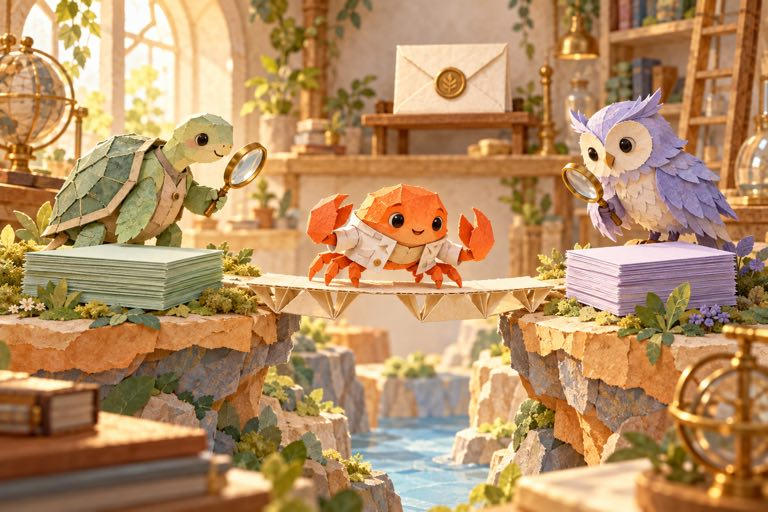

*The experiment should cross a new set of prompts before it crosses into production.*



*A protocol for accepting our new components, not a retrospective certification of the entire public lineage.*

<a id="instyle-two-stage"></a>

## 5b. Branch A: the two-stage stack

Branch A is Nishant Dahal's *part two* stack, re-implemented here. Its members: a style n-gram SVC fit on train plus his public pool of 75,783 competition-style passages (balanced class weights), two LoRA classifiers with the LoRA24 readout (the first 27 of Qwen3-14B-Base's 40 layers; the first 32 of Qwen2.5-14B's 48), and a fully fine-tuned DeBERTa-v3-large. Each of the three neural members was trained in two stages: first on the public pool (one or two epochs, class-weighted), then on the 2,699 competition passages at a lower learning rate. Part two's own prompt-grouped CV: SVC 0.473, Qwen3-14B 0.611, Qwen2.5-14B 0.569, DeBERTa 0.546, blend 0.642 (0.620 public). His account of what mattered most is the pool: the same Qwen3-14B recipe went from 0.569 to 0.611 when the pool grew from 35,000 to 84,000 cleaner passages.

The adapters are folded into the trunk weights once; the 14B trunks are split over the two T4s. One detail he found that only shows up on Kaggle: the hosted Qwen3 tokenizer ends passages with `<|im_end|>` while the checkpoints were trained with `<|endoftext|>` appended, which changed 14% of his first checkpoints' predictions. His new checkpoints record their training end token; for the older checkpoint without it, this notebook picks the end token that best reproduces the training fit on 64 training rows.

**Our additions to the branch.** On grouped test rows every member's centred head adds its evidence (his twins at his weights), and a **shared-prompt Gaussian head** (section 4) fitted on each member's training-row features adds a joint decoding of every group of 2 to 18 passages, exact over label tuples for pairs and triples. In our harness the Gaussian head beat the matching centred head in all 68 view-by-scenario cells, and adding it to the two-stage features was worth about +0.005 on the public leaderboard in versions 3 to 4. The older 14B checkpoint of his first notebook and our own two seeds (the cell after the next) stay in the branch at small weights as extra, differently trained voices: our seeds are the same LoRA24 architecture on Qwen3-8B, trained with our own trainer on a 38,642-passage pool we built from fifteen public datasets ([pool](https://www.kaggle.com/datasets/prvsiyan/ntl-public-in-style-pool-v1), [adapters](https://www.kaggle.com/datasets/prvsiyan/ntl-two-stage-lora-adapters-v1)); prompt-grouped OOF 0.5675, 0.645 with true-prompt centring.

The saved report of our seeds covers **seed 0 and folds 0-3** (prompt-grouped plain-head balanced accuracy 0.5675; 0.6447 with oracle prompt centring, a diagnostic, not a hidden-test forecast). The public checkpoints' numbers are their author's, on his folds, a different protocol. None of this is the complete nested two-scheme acceptance gate we use for a new Fable component; the public-leaderboard increments quoted above are whole-notebook changes, not isolated causal estimates per member.


In [ ]:
# ============================================================ 5a. branch A: the public two-stage LoRAs and the two-stage DeBERTa
from safetensors.torch import load_file as _load_st


def load_merged_trunk(base_dir, keep, dtype):
    """The first `keep` decoder layers of a Qwen base, final norm removed, spread over both T4s when it cannot fit on one."""
    cfg = AutoConfig.from_pretrained(base_dir)
    cfg.num_hidden_layers, cfg.use_cache = keep, False
    if getattr(cfg, 'layer_types', None) is not None:
        cfg.layer_types = cfg.layer_types[:keep]
    hd = getattr(cfg, 'head_dim', cfg.hidden_size // cfg.num_attention_heads)
    per_layer = 2 * cfg.hidden_size * (cfg.num_attention_heads + cfg.num_key_value_heads) * hd + 3 * cfg.hidden_size * cfg.intermediate_size
    gib = 2 * (cfg.vocab_size * cfg.hidden_size + keep * per_layer) / 2 ** 30
    if gib > 13 and torch.cuda.device_count() > 1:
        model = AutoModel.from_pretrained(base_dir, config=cfg, dtype=dtype, device_map='auto',
                                          max_memory={i: '13GiB' for i in range(torch.cuda.device_count())}).eval()
    else:
        model = AutoModel.from_pretrained(base_dir, config=cfg, dtype=dtype).to('cuda:0').eval()
    model.norm = torch.nn.Identity()
    print(f'  trunk {os.path.basename(base_dir)}: {keep} layers, {gib:.1f} GiB fp16, devices {sorted({str(p.device) for p in model.parameters()})}', flush=True)
    return model


@torch.no_grad()
def merge_adapter_into(model, adapter_dir):
    """Fold a peft-format LoRA into the trunk weights: W <- W + (B A) * alpha / r, so inference needs no adapter library."""
    acfg = json.load(open(os.path.join(adapter_dir, 'adapter_config.json')))
    scale = acfg['lora_alpha'] / acfg['r']
    sd = _load_st(os.path.join(adapter_dir, 'adapter_model.safetensors'))
    mods = dict(model.named_modules())
    n = 0
    for k, A in sd.items():
        if '.lora_A.' not in k:
            continue
        path = k.split('.lora_A.')[0]
        lin = mods[path[path.index('layers.'):]]
        B = sd[k.replace('.lora_A.', '.lora_B.')]
        lin.weight.add_(((B.float().to(lin.weight.device) @ A.float().to(lin.weight.device)) * scale).to(lin.weight.dtype))
        n += 1
    print(f'  merged {n} LoRA pairs from {os.path.basename(os.path.dirname(adapter_dir))}', flush=True)


@torch.no_grad()
def two_stage_features(model, tok, norms, layers, texts, max_len, eos_id, bs):
    """Masked mean (first token excluded) of the pooled layers, each through its own LayerNorm, concatenated: (n, len(layers) * hidden).
    A batch that overflows fp16 is redone in bf16; a batch that overflows the T4's memory is redone one passage at a time."""
    ids = [x + [eos_id] for x in tok(list(texts), add_special_tokens=False, truncation=True, max_length=max_len)['input_ids']]
    order = np.argsort([len(x) for x in ids], kind='stable')
    H = model.config.hidden_size
    Z = np.zeros((len(ids), H * len(layers)), np.float32)
    dev0 = model.embed_tokens.weight.device
    redone = 0

    def embed(idx):
        nonlocal redone
        enc = tok.pad({'input_ids': [ids[i] for i in idx]}, return_tensors='pt').to(dev0)
        hs = model(**enc, output_hidden_states=True, use_cache=False).hidden_states
        if not all(torch.isfinite(hs[l]).all() for l in layers):
            redone += 1
            model.to(torch.bfloat16)
            hs = model(**enc, output_hidden_states=True, use_cache=False).hidden_states
            model.to(torch.float16)
        m = enc['attention_mask'].unsqueeze(-1).float().to('cuda:0')
        m[:, 0] = 0
        den = m.sum(1).clamp(min=1)
        Z[idx] = torch.cat([nm((hs[l].to('cuda:0').float() * m).sum(1) / den) for l, nm in zip(layers, norms)], -1).cpu().numpy()
        del hs, enc

    for b0 in range(0, len(order), bs):
        idx = order[b0:b0 + bs]
        try:
            embed(idx)
        except torch.cuda.OutOfMemoryError:
            torch.cuda.empty_cache()
            for i in idx:
                embed([i])
    if redone:
        print(f'  {redone} batches redone in bf16', flush=True)
    return np.nan_to_num(Z)


def find_base(base_spec):
    for c in sorted(glob.glob('/kaggle/input/**/config.json', recursive=True)):
        try:
            d = json.load(open(c))
        except Exception:
            continue
        if all(d.get(k) == v for k, v in base_spec.items()):
            return os.path.dirname(c)
    raise FileNotFoundError(f'base model {base_spec} not attached')


def gaussian_on_features(name, Ztr, Zte, w, d=None, T=None):
    """Our addition on every branch-A member: a shared-prompt Gaussian head fitted on the member's training-row features, scored jointly
    inside the detected test groups (exact over label tuples for pairs and triples)."""
    prm = fit(Ztr, y, PROMPT, dict(GAUSS_SETTING, d=d or GAUSS_LORA['d']))
    prm['T1'] = prm['Tg'] = T or GAUSS_LORA['T']
    print(f'  gauss_{name}: d {prm["info"]["d"]}, shrinkage e/p {prm["info"]["a_e"]}/{prm["info"]["a_p"]}, lam pct {prm["info"]["lam_pct"]}', flush=True)
    if ROWS_A.any():
        lab = np.unique(G_A[ROWS_A], return_inverse=True)[1]
        U = transform(Zte[ROWS_A], prm)
        LP = scores(None, lab, prm, U=U)
        add_member('gauss_' + name, np.exp(LP), rows=ROWS_A, weight=w, target=LOGIT_A)
        if CRF['on']:
            COUPLINGS.append(coupling_tables(U, lab, prm, CRF['nmax']))
    if TINY:
        st_idx, st_g = self_test_rows()
        print(f'  gauss_{name} self-test on {len(st_idx)} training rows (seen in training): acc {np.mean(scores(Ztr[st_idx], st_g, prm).argmax(1) == y[st_idx]):.2f}', flush=True)
        if CRF['on']:   # exercise the joint-decoding path on three training pairs (the 3-row file has no groups)
            Ut = transform(Ztr[st_idx[:6]], prm)
            ct = coupling_tables(Ut, np.array([0, 0, 1, 1, 2, 2]), prm, CRF['nmax'])
            q = crf_scores(np.log(np.clip(np.exp(scores(None, np.arange(6), prm, U=Ut)), 1e-9, 1)), [ct], 6, CRF['t'], CRF['beta'])
            print(f'  crf self-test: {len(ct)} pair tables, marginals finite {bool(np.isfinite(q).all())}, acc {np.mean(q.argmax(1) == y[st_idx[:6]]):.2f}', flush=True)


def public_two_stage(key, ck_name, w, twin_w, gauss_w, bs, base_spec):
    hits = sorted(glob.glob(f'/kaggle/input/**/{ck_name}/meta.json', recursive=True))
    assert hits, f'checkpoint {ck_name} not attached'
    ck = os.path.dirname(hits[0])
    meta = json.load(open(hits[0]))
    cols = [LAB2I[l] for l in meta['labels']]          # the checkpoint's head order -> our label order
    cfg = meta['cfg']
    base = find_base(base_spec)
    tok = AutoTokenizer.from_pretrained(base)
    tok.padding_side = 'right'
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    model = load_merged_trunk(base, cfg['keep'], torch.float16)
    merge_adapter_into(model, os.path.join(ck, 'adapter'))
    heads = _load_st(os.path.join(ck, 'heads.safetensors'))
    norms = torch.nn.ModuleList([torch.nn.LayerNorm(model.config.hidden_size) for _ in cfg['layers']]).to('cuda:0').float()
    norms.load_state_dict({k[len('norms.'):]: v for k, v in heads.items() if k.startswith('norms.')})
    Wp, bp = heads['plain.weight'].float().numpy(), heads['plain.bias'].float().numpy()
    Wc, bc = heads['centered.weight'].float().numpy(), heads['centered.bias'].float().numpy()
    feats = lambda texts, eos: two_stage_features(model, tok, norms, cfg['layers'], texts, cfg['max_len'], eos, bs)
    plain = lambda Z: full_prob(softmax_rows(Z @ Wp.T + bp), cols)
    # the end token: the checkpoint's own when it records one; otherwise the candidate that reproduces the training fit best on training rows
    if 'eos_id' in cfg:
        eos = int(cfg['eos_id'])
        print(f'  end token {eos} from the checkpoint (this tokenizer: {tok.eos_token_id})', flush=True)
    else:
        probe = TR[:64]
        accs = {e: float(np.mean(plain(feats(probe, e)).argmax(1) == y[:64])) for e in EOS_CANDIDATES}
        eos = max(accs, key=accs.get)
        print(f'  end token picked on 64 training rows: {accs} -> {eos}', flush=True)
    Ztr = feats(TR, eos)                                # training-row features: the Gaussian head and the self-tests need them
    acc = float(np.mean(plain(Ztr[:40]).argmax(1) == y[:40]))
    print(f'  {key} in-sample check on 40 training rows: acc {acc:.2f}', flush=True)
    assert acc > 0.5, f'{key} does not reproduce its training fit'
    Z = feats(TE, eos)
    add_member(key, plain(Z), weight=w, target=LOGIT_A)
    if ROWS_A.any():
        Zc = group_centre_dense(Z[ROWS_A], G_A[ROWS_A])
        add_member(key + '_twin', full_prob(softmax_rows(Zc @ Wc.T + bc), cols), rows=ROWS_A, weight=twin_w, target=LOGIT_A)
    if TINY:
        st_idx, st_g = self_test_rows()
        print(f'  {key} twin self-test on {len(st_idx)} training rows: acc {np.mean(full_prob(softmax_rows(group_centre_dense(Ztr[st_idx], st_g) @ Wc.T + bc), cols).argmax(1) == y[st_idx]):.2f}', flush=True)
    if gauss_w > 0:
        gaussian_on_features(key, Ztr, Z, gauss_w)
    del model, Z, Ztr, heads, norms
    gc.collect()
    torch.cuda.empty_cache()


@torch.no_grad()
def two_stage_deberta():
    """The fully fine-tuned DeBERTa-v3-large of part two (mean of the last layer, one linear head), copied to local disk first."""
    hits = sorted(glob.glob('/kaggle/input/**/deberta_v3_large/meta.json', recursive=True))
    assert hits, 'deberta_v3_large checkpoint not attached (dataset nishantdahal/ntl-handwriting-blend)'
    ck = os.path.dirname(hits[0])
    local = '/tmp/deberta_v3_large'
    shutil.copytree(ck, local, dirs_exist_ok=True)   # one long copy beats many small reads from the dataset mount
    meta = json.load(open(os.path.join(local, 'meta.json')))
    cols = [LAB2I[l] for l in meta['labels']]
    etok = AutoTokenizer.from_pretrained(os.path.join(local, 'encoder'))
    enc = AutoModel.from_pretrained(os.path.join(local, 'encoder'), dtype=torch.float32).to('cuda:0').eval()
    head = _load_st(os.path.join(local, 'head.safetensors'))
    Wd, bd = head['weight'].float().numpy(), head['bias'].float().numpy()

    def feats(texts):
        ids = etok(list(texts), truncation=True, max_length=meta['max_len'])['input_ids']
        order = np.argsort([len(x) for x in ids], kind='stable')
        Z = np.zeros((len(ids), enc.config.hidden_size), np.float32)
        for b0 in range(0, len(order), 32):
            idx = order[b0:b0 + 32]
            bt = etok.pad({'input_ids': [ids[i] for i in idx]}, return_tensors='pt').to('cuda:0')
            m = bt['attention_mask'].unsqueeze(-1).float()
            Z[idx] = ((enc(**bt).last_hidden_state * m).sum(1) / m.sum(1).clamp(min=1)).cpu().numpy()
        return Z

    Ztr = feats(TR)
    acc = float(np.mean(full_prob(softmax_rows(Ztr[:40] @ Wd.T + bd), cols).argmax(1) == y[:40]))
    print(f'  p2_deberta in-sample check on 40 training rows: acc {acc:.2f}', flush=True)
    assert acc > 0.5, 'the DeBERTa checkpoint does not reproduce its training fit'
    Z = feats(TE)
    add_member('p2_deberta', full_prob(softmax_rows(Z @ Wd.T + bd), cols), weight=W_DEBERTA, target=LOGIT_A)
    if GAUSS_DEBERTA_W > 0:
        gaussian_on_features('p2_deberta', Ztr, Z, GAUSS_DEBERTA_W)
    del enc, Z, Ztr
    gc.collect()
    torch.cuda.empty_cache()


if not SMOKE:
    for key, ck_name, w, twin_w, gauss_w, bs, base_spec in PUBLIC_TWOSTAGE:
        if key.startswith('p2_'):
            public_two_stage(key, ck_name, w, twin_w, gauss_w, bs, base_spec)   # part two's members are required
        else:
            guard(key, public_two_stage, key, ck_name, w, twin_w, gauss_w, bs, base_spec)
    two_stage_deberta()

In [ ]:
# ============================================================ 5c. our own two-stage LoRAs (stage 1: our 38,642-passage public pool; stage 2: host rows)
def two_stage_lora(key, sub_dir, w, twin_w, bs=12):
    """Rebuild one of our two-stage checkpoints with the vendored trainer module (own LoRA implementation, no peft), pool the 8 layers
    through their LayerNorms, read the plain head on every row and the centred head on cluster-centred features of grouped rows."""
    import sys, importlib
    hits = sorted(glob.glob('/kaggle/input/**/adapters/lora_cls.py', recursive=True))
    assert hits, 'attach the two-stage LoRA adapters dataset'
    sys.path.insert(0, os.path.dirname(hits[0]))
    lora_cls = importlib.import_module('lora_cls')
    lora_cls.EVAL_BS = bs
    root = sorted(glob.glob(f'/kaggle/input/**/adapters/q8b_L24_ctr/{sub_dir}/meta.json', recursive=True))
    assert root, f'adapter {sub_dir} not attached'
    model, tok, meta = lora_cls.load_for_inference(os.path.dirname(root[0]), device=DEV)
    assert meta['labels'] == LABELS and meta.get('init_adapter'), 'not a stage-2 checkpoint in our label order'
    hp = meta['hp']

    def run(texts):
        seqs = lora_cls.encode(tok, texts, hp['max_len'], hp['bos'], hp.get('bos_id'))
        out = lora_cls.predict_all(model, seqs, list(range(len(seqs))), tok.pad_token_id, DEV, bs=bs)
        return out['z'], out['lp'], out['bad']

    if TINY:   # in-sample check on training rows the checkpoint was fitted on
        _, lp, _ = run(TR[:40])
        acc = float(np.mean(lp.argmax(1) == y[:40]))
        print(f'  {key} in-sample check on 40 training rows: acc {acc:.2f}', flush=True)
        assert acc > 0.5, f'{key} does not reproduce its training fit'
    Z, lp, bad = run(TE)
    print(f'  {key}: stage 1 {os.path.basename(meta["init_adapter"])}, {meta["steps"]} stage-2 steps, non-finite rows {bad}', flush=True)
    add_member(key, softmax_rows(lp), weight=w, target=LOGIT_A)
    if ROWS_A.any():
        Zc = group_centre_dense(Z[ROWS_A], G_A[ROWS_A])
        with torch.no_grad():
            lc = model.logits_ctr(torch.tensor(Zc, device=DEV)).float().cpu().numpy()
        add_member(key + '_twin', softmax_rows(lc), rows=ROWS_A, weight=twin_w, target=LOGIT_A)
    gauss_w = GAUSS_LORA_W.get(key, 0.0)
    if gauss_w > 0:   # shared-prompt Gaussian head on this LoRA's features (same setting as for the public checkpoints)
        Ztr, _, _ = run(TR)
        gaussian_on_features(key, Ztr, Z, gauss_w)
        del Ztr
    del model
    gc.collect()
    torch.cuda.empty_cache()


if not SMOKE:
    for key, sub_dir, w, twin_w in TWOSTAGE:
        guard(key, two_stage_lora, key, sub_dir, w, twin_w)


def write_submission(P, note):
    """argmax of P -> submission.parquet (schema checked). Called once here with branch A alone as an anchor, and again at the end."""
    sub = pd.DataFrame({'id': test['id'], 'model': [LABELS[i] for i in P.argmax(1)]})
    assert sub['id'].is_unique and sub['model'].isin(LABELS).all() and len(sub) == len(test) and sub['model'].notna().all()
    sub.to_parquet('submission.parquet', index=False)
    print(f'submission written ({note}): ' + ', '.join(f'{k} {v}' for k, v in sub['model'].value_counts().head(6).items()), flush=True)


def balance(P):
    """Full Sinkhorn, one scale per class, until every class holds 1/18 of the probability mass (skipped on the 3-row file)."""
    if len(P) < 50:
        return P
    c = np.ones(K)
    target = np.full(K, len(P) / K)
    for _ in range(SINKHORN_ITERS):
        R = P * c
        R /= R.sum(1, keepdims=True)
        c *= target / (R.sum(0) + 1e-12)
    P = P * c
    return P / P.sum(1, keepdims=True)


write_submission(balance(softmax_rows(LOGIT_A)), 'anchor: branch A alone, balanced; replaced by the full result at the end')

<a id="instyle-token-heads"></a>

## 6. Token attention and UltraBERT

Two small attention-pooling heads over frozen token states (Qwen3.5-9B layer 18 and DeBERTa-v3-large layer 23) and the UltraBERT-380M 5-fold ensemble complete the member list.

In [ ]:
# ============================================================ 6. token-attention heads + UltraBERT
class TokenAttention(torch.nn.Module if torch is not None else object):   # the module of the public training kernels (lucasboesen/name-that-llm-train-tokattn, -tokattn2)
    def __init__(self, k, h=4096):
        super().__init__()
        self.drop, self.proj, self.score, self.out = torch.nn.Dropout(0.2), torch.nn.Linear(h, 64), torch.nn.Linear(64, 1), torch.nn.Linear(128, k)

    def forward(self, x, m):
        h = torch.tanh(self.proj(self.drop(x)))
        a = torch.softmax(self.score(h).squeeze(-1).masked_fill(~m, -1e4), -1).unsqueeze(-1)
        mf = m.unsqueeze(-1).float()
        return self.out(self.drop(torch.cat([(h * mf).sum(1) / mf.sum(1).clamp(min=1), (a * h).sum(1)], -1)))


@torch.no_grad()
def token_attention_probs(texts, head_file, backbone, bs=8):
    hits = sorted(glob.glob('/kaggle/input/**/' + head_file, recursive=True))
    assert hits, f'training-kernel output holding {head_file} not attached'
    d = torch.load(hits[0], map_location='cpu')
    assert list(d['classes']) == LABELS
    decoder = d.get('decoder', True)
    path = find_checkpoint('qwen3_5') if backbone == 'qwen3_5' else find_checkpoint(None, dir_name='deberta-v3-large')
    assert path, f'backbone {backbone} not attached'
    path = localise(path)
    cfg = AutoConfig.from_pretrained(path)
    if decoder:
        tc = getattr(cfg, 'text_config', None) or cfg
        tc.num_hidden_layers = d['keep']
        if getattr(tc, 'layer_types', None):
            tc.layer_types = tc.layer_types[:d['keep']]
        lm = AutoModel.from_pretrained(path, config=cfg, dtype=torch.float16, device_map='auto').eval()
    else:
        lm = AutoModel.from_pretrained(path, dtype=torch.float32).to(DEV).eval()
    tok = AutoTokenizer.from_pretrained(path)
    tok.padding_side = 'right'
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    H = d.get('hidden', 4096)
    net = TokenAttention(K, H)
    net.load_state_dict(d['state_dict'])
    dev = lm.get_input_embeddings().weight.device
    net, mu, sd = net.to(dev).eval(), d['mu'].float().to(dev), d['sd'].float().to(dev)
    ids = tok(list(texts), add_special_tokens=not decoder, truncation=True, max_length=d['max_len'])['input_ids']
    P = np.zeros((len(texts), K))
    order = np.argsort([len(t) for t in ids])
    for b0 in range(0, len(order), bs):
        idx = order[b0:b0 + bs]
        batch = tok.pad({'input_ids': [ids[i] for i in idx]}, return_tensors='pt').to(dev)
        out = lm(input_ids=batch['input_ids'], attention_mask=batch['attention_mask'], output_hidden_states=True)
        hs = (out.hidden_states if getattr(out, 'hidden_states', None) is not None else out.language_model_outputs.hidden_states)[d['layer']]
        n = batch['attention_mask'].sum(1)
        T = max(int(n.max()) - 1, 1)
        x = torch.zeros(len(idx), T, H, device=dev)
        m = torch.zeros(len(idx), T, dtype=torch.bool, device=dev)
        for r in range(len(idx)):   # first token dropped, states rounded through fp16, as in training
            k = int(n[r]) - 1
            if k > 0:
                x[r, :k] = ((torch.nan_to_num(hs[r, 1:k + 1].to(dev).float()).half().float() - mu) / sd).clamp(-8, 8)
                m[r, :k] = True
        P[idx] = torch.softmax(net(x, m), -1).cpu().numpy()
        del hs, out, batch
    del lm
    gc.collect()
    torch.cuda.empty_cache()
    return P


@torch.no_grad()
def ultrabert_probs(texts):
    from transformers import AutoModelForSequenceClassification
    folds = None
    for root in glob.glob('/kaggle/input/**/ultrabert-380m-ntl', recursive=True):
        fs = [f for f in sorted(glob.glob(os.path.join(root, 'fold*'))) if os.path.exists(os.path.join(f, 'config.json'))
              and json.load(open(os.path.join(f, 'config.json'))).get('model_type') == 'ultrabert']
        if len(fs) == 5:
            folds = fs
            break
    assert folds, 'ultrabert-380m-ntl (5 folds) not attached'
    tok = AutoTokenizer.from_pretrained(folds[0], trust_remote_code=True)
    ids = tok(texts, truncation=True, max_length=512)['input_ids']
    order = np.argsort([len(e) for e in ids])
    P = np.zeros((len(texts), K))
    for fp in folds:
        em = AutoModelForSequenceClassification.from_pretrained(fp, trust_remote_code=True, dtype=torch.float16, attn_implementation='sdpa').to(DEV).eval()
        cols = [LAB2I[em.config.id2label[i]] for i in range(len(em.config.id2label))]
        for b0 in range(0, len(order), 32):
            idx = order[b0:b0 + 32]
            b = tok.pad({'input_ids': [ids[j] for j in idx]}, return_tensors='pt').to(DEV)
            P[np.ix_(idx, cols)] += em(**b).logits.float().softmax(-1).cpu().numpy() / len(folds)
        del em
        gc.collect()
        torch.cuda.empty_cache()
    return P


def tokattn_member(key, head_file, backbone):
    if TINY:   # in-sample check on training rows the head was fitted on: must be high, or the checkpoint is not being reproduced
        acc = float(np.mean(token_attention_probs(TR[:40], head_file, backbone).argmax(1) == y[:40]))
        print(f'  {key} in-sample check on 40 training rows: acc {acc:.2f}', flush=True)
        assert acc > 0.5, f'{key} does not reproduce its training fit'
    add_member(key, token_attention_probs(TE, head_file, backbone))


if not SMOKE:
    for key, head_file, backbone in TOKATTN_HEADS:
        guard(key, tokattn_member, key, head_file, backbone)
    guard('ultrabert', lambda: add_member('ultrabert', ultrabert_probs(TE)))



*The distinction matters most when a public/private class mixture shifts.*

<a id="instyle-balancing"></a>

## 7. Two branches, one mix, one balancing

Each branch sums its members' log-probabilities and becomes a probability vector. The blend uses 85% branch A and 15% branch B (version 5's early-layer mix is off). The balancing step now runs 300 iterations with one scale per class, as in part two. The weights, grouping cuts and class-mass balancing are inherited settings; this edition does not retune them. Hard per-prompt assignment is deliberately absent: several competitors report that it raises grouped CV and lowers the leaderboard, because the hidden pool holds few passages per prompt; soft centring and joint decoding of small groups are the tools for that regime.

The final Sinkhorn iterations target equal **soft class mass** across the pool. That is a heuristic, not a consequence of balanced accuracy: the metric gives each author's recall equal weight, while the competition explicitly allows unequal and changing test class frequencies. An incorrect balancing assumption can therefore hurt. This is distinct from assigning every author exactly once within a detected group; hard assignment has its own assumptions and failure modes.

Within-family gates remain off in this version. Every passage must still receive exactly one valid author label, in the same row order as the input, and the final cell checks the submission schema before saving.


<a id="instyle-atlas"></a>

## 6b. ATLAS: which source makes this text most likely?

Every member so far reads a representation of the passage and classifies it. ATLAS (Ko et al., arXiv 2610.19583) asks the opposite question: under which of the 18 sources is the passage itself most *likely*, token by token? Joseph Adamski's public adapter turns Qwen3-8B-Base into such a model: a LoRA on every attention projection whose up-projection is chosen by the hypothesised source, plus a learned control embedding per source prepended to the text; it was trained for five epochs on the 2,699 competition passages only. For each passage the scorer runs the 18 source hypotheses, collects the per-token log-probabilities, and reads them out as in the paper: for every token and source, the summed disadvantage against the other sources is clipped at zero and exponentiated at temperatures 1, 2, 4 and 8, then averaged over tokens and temperatures. The implementation below is our own; it loads his adapter tensors by name and checks their shapes.


In [ ]:
# ============================================================ 6b. ATLAS: source-conditioned next-token likelihood (own implementation)
# Model (arXiv:2610.19583, public adapter bundle josephadamski91/ntl-atlas-qwen3-8b-v1): a frozen Qwen3-8B-Base causal LM; on every
# attention projection a LoRA whose down-projection A is shared and whose up-projection B is chosen by the hypothesised source; a learned
# control embedding per source prepended to the passage. For each passage and each of the 18 sources the model gives per-token
# log-probabilities; the readout clips the pairwise evidence per token, exp(-sum_j max(lp_j - lp_k, 0) / T), averages over tokens and over
# T in {1, 2, 4, 8}, and normalises over sources. Used only on rows whose top-2 margin after the branch mix is below ATLAS['margin'].
class SourceLoRA(torch.nn.Module):
    """base linear + (x A^T) B_s^T * alpha / r, where s is the source index of each batch row."""
    def __init__(self, base, n_sources, rank, alpha, route):
        super().__init__()
        self.base, self.route, self.scale = base, route, alpha / rank
        dev = base.weight.device
        self.a = torch.nn.Parameter(torch.zeros(rank, base.in_features, device=dev, dtype=torch.float32))
        self.b = torch.nn.Parameter(torch.zeros(n_sources, base.out_features, rank, device=dev, dtype=torch.float32))

    def forward(self, x):
        out = self.base(x)
        h = torch.nn.functional.linear(x.float(), self.a)
        sel = self.b.index_select(0, self.route['labels'].to(self.b.device))
        return out + (torch.bmm(h, sel.transpose(1, 2)) * self.scale).to(out.dtype)


@torch.no_grad()
def atlas_probabilities(texts, deadline):
    """(n, K) ATLAS probabilities in our label order; rows are processed most-uncertain-first by the caller, so a deadline stop leaves the
    rows that matter least without ATLAS (they keep their mixed probabilities)."""
    from transformers import AutoModelForCausalLM
    from safetensors.torch import load_file as _ld
    bundles = sorted(glob.glob('/kaggle/input/**/atlas_bundle.json', recursive=True))
    assert len(bundles) == 1, f'{len(bundles)} ATLAS bundles attached'
    root = os.path.dirname(bundles[0])
    meta = json.load(open(bundles[0]))
    cfg = meta['training_config']
    cols = [LAB2I[l] for l in meta['labels']]
    base_dir = find_base(dict(model_type='qwen3', hidden_size=4096, num_hidden_layers=36))
    tok = AutoTokenizer.from_pretrained(base_dir)
    tok.padding_side = 'right'
    if tok.pad_token_id is None:
        tok.pad_token = tok.eos_token
    lm = AutoModelForCausalLM.from_pretrained(base_dir, dtype=torch.float16, attn_implementation='sdpa', device_map='auto',
                                              max_memory={i: int(torch.cuda.get_device_properties(i).total_memory - 4 * 2 ** 30) for i in range(torch.cuda.device_count())}).eval()
    assert all(p.device.type == 'cuda' for p in lm.parameters()), 'the 16-bit Qwen3-8B does not fit on the GPUs'
    lm.config.use_cache = False
    route = {'labels': None}
    n_src = len(meta['labels'])
    for name, mod in list(lm.named_modules()):
        if name.split('.')[-1] in ('q_proj', 'k_proj', 'v_proj', 'o_proj') and isinstance(mod, torch.nn.Linear):
            parent, leaf = name.rsplit('.', 1)
            setattr(lm.get_submodule(parent), leaf, SourceLoRA(mod, n_src, cfg['rank'], cfg['alpha'], route))
    emb = lm.get_input_embeddings().weight
    control = torch.nn.Parameter(torch.zeros(n_src, 1, emb.shape[1], device=emb.device, dtype=torch.float32))
    state = _ld(os.path.join(root, 'adapters.safetensors'))
    own = {('base.' + n): p for n, p in lm.named_parameters() if n.endswith(('.a', '.b'))}
    own['control'] = control
    assert set(state) == set(own), f'adapter keys differ from this implementation: {sorted(set(state) ^ set(own))[:4]}'
    for k, v in state.items():
        assert own[k].shape == v.shape and torch.isfinite(v).all(), k
        own[k].copy_(v.to(own[k].device, own[k].dtype))
    print(f'  ATLAS: {len(state)} adapter tensors loaded, {sum(isinstance(m, SourceLoRA) for m in lm.modules())} source-routed projections', flush=True)
    head = lm.get_output_embeddings()
    temps = cfg['prod_temperatures']

    def token_logp(ids, mask, labels):
        route['labels'] = labels
        te = lm.get_input_embeddings()(ids)
        ctrl = control.index_select(0, labels.to(control.device)).to(te.dtype).to(te.device)
        hidden = lm.model(inputs_embeds=torch.cat([ctrl, te], 1), attention_mask=torch.cat([mask.new_ones(len(ids), 1), mask], 1),
                          use_cache=False).last_hidden_state[:, 1:-1]
        targets = ids[:, 1:]
        out = []
        for s0 in range(0, hidden.shape[1], cfg['head_chunk_tokens']):
            h, yv = hidden[:, s0:s0 + cfg['head_chunk_tokens']], targets[:, s0:s0 + cfg['head_chunk_tokens']]
            logits = head(h.to(head.weight.device)).float()
            out.append(-torch.nn.functional.cross_entropy(logits.reshape(-1, logits.shape[-1]), yv.to(logits.device).reshape(-1), reduction='none').reshape(yv.shape))
        return torch.cat(out, 1).to(ids.device)

    def readout(lp, mask):   # lp (b, S, T): argmax-prod with clipped pairwise evidence, averaged over tokens and temperatures
        dis = (lp.unsqueeze(1) - lp.unsqueeze(2)).clamp_min(0).sum(2)
        valid = mask.float().unsqueeze(1)
        sc = torch.stack([(torch.exp(-dis / float(t)) * valid).sum(-1) / valid.sum(-1).clamp_min(1) for t in temps]).mean(0)
        sc = sc.clamp_min(1e-12)
        return sc / sc.sum(-1, keepdim=True)

    tokens = tok(list(texts), truncation=True, max_length=cfg['max_length'])['input_ids']
    dev0 = lm.get_input_embeddings().weight.device
    P = np.full((len(texts), K), np.nan, np.float32)
    bs, chunk = ATLAS['bs'], ATLAS['source_chunk']
    t_start, done = time.time(), 0
    def score_rows(idx, chunk):
        pack = tok.pad({'input_ids': [tokens[i] for i in idx]}, padding=True, return_tensors='pt').to(dev0)
        ids, mask = pack['input_ids'], pack['attention_mask']
        parts = []
        for f0 in range(0, n_src, chunk):
            n = min(n_src, f0 + chunk) - f0
            src = torch.arange(f0, f0 + n, device=dev0).repeat_interleave(len(idx))
            lp = token_logp(ids.repeat(n, 1), mask.repeat(n, 1), src)
            parts.append(lp.reshape(n, len(idx), -1).transpose(0, 1))
        return readout(torch.cat(parts, 1), mask[:, 1:]).cpu().numpy()

    order = np.argsort([len(t) for t in tokens], kind='stable')   # similar lengths together: less padding, less memory
    for b0 in range(0, len(texts), bs):
        if time.time() > deadline:
            print(f'  ATLAS deadline reached after {done} of {len(texts)} rows; the rest keep their mixed probabilities', flush=True)
            break
        idx = [int(i) for i in order[b0:b0 + bs]]
        try:
            pr = score_rows(idx, chunk)
        except torch.cuda.OutOfMemoryError:   # long passages: one row and one source at a time
            torch.cuda.empty_cache()
            pr = np.concatenate([score_rows([i], 1) for i in idx], 0)
        P[idx] = full_prob(pr, cols)
        done += len(idx)
        if b0 % (25 * bs) == 0:
            el = time.time() - t_start
            print(f'  ATLAS {done}/{len(texts)} rows, {el:.0f}s, projected {el / done * len(texts):.0f}s', flush=True)
    del lm, state, control
    gc.collect()
    torch.cuda.empty_cache()
    return P

In [ ]:
# ============================================================ 7. two branches -> one mix -> full balancing -> submission
if CRF['on'] and COUPLINGS and ROWS_A.any():   # joint decoding of branch-A groups of 2-3: plain unary / t + beta * sum of the Gaussian couplings
    def crf_stage():
        rows_idx = np.flatnonzero(ROWS_A)
        n_groups = 0
        for gl, (ii, _) in COUPLINGS[0].items():
            g = rows_idx[ii]
            Q = joint_table(LOGIT_A_PLAIN[g] / CRF['t'], np.zeros((len(g), len(g), K, K)))
            for cv in COUPLINGS:
                Q = Q + CRF['beta'] * cv[gl][1]
            LOGIT_A[g] = exact_marginals(Q, 1.0, True)   # log marginals: their softmax is the joint posterior's marginal
            n_groups += 1
        print(f'joint decoding replaced branch A on {n_groups} groups of 2-{CRF["nmax"]} ({len(COUPLINGS)} Gaussian views, t {CRF["t"]}, beta {CRF["beta"]})', flush=True)
    guard('crf', crf_stage)
P_A, P_B = softmax_rows(LOGIT_A), softmax_rows(LOGIT)
if EARLY['mix'] > 0:
    P_A = (1.0 - EARLY['mix']) * P_A + EARLY['mix'] * P_EARLY   # version 5: the early-layer classifier joins branch A as a probability mix
print(f'branch A and B argmax agree on {int((P_A.argmax(1) == P_B.argmax(1)).sum())} of {len(TE)} rows', flush=True)
P = MIX_A * P_A + (1.0 - MIX_A) * P_B
assert np.isfinite(P).all() and np.allclose(P.sum(1), 1.0)
if ATLAS['w'] > 0 and not SMOKE:   # version 7: ATLAS on the rows whose top-2 margin is small (every row on the tiny interactive file)
    srt = np.sort(P, axis=1)
    margin = srt[:, -1] - srt[:, -2]
    rows = np.flatnonzero(margin < ATLAS['margin']) if len(TE) >= 50 else np.arange(len(TE))
    rows = rows[np.argsort(margin[rows])]           # most uncertain first, so a deadline stop costs the least
    print(f'ATLAS rows: {len(rows)} of {len(TE)} (margin < {ATLAS["margin"]})', flush=True)
    def atlas_stage():
        PA = atlas_probabilities([TE[i] for i in rows], deadline=T0 + ATLAS['deadline_h'] * 3600)
        ok = np.isfinite(PA[:, 0])
        P[rows[ok]] = (1.0 - ATLAS['w']) * P[rows[ok]] + ATLAS['w'] * PA[ok]
        print(f'ATLAS applied on {int(ok.sum())} rows; argmax changed on {int((P[rows[ok]].argmax(1) != (MIX_A * P_A + (1.0 - MIX_A) * P_B)[rows[ok]].argmax(1)).sum())}', flush=True)
        if TINY:   # the commit run scores 200 training rows (many batches, mixed lengths, as in the hidden run): must be far above chance
            PT = atlas_probabilities(TR[:200], deadline=T0 + ATLAS['deadline_h'] * 3600)
            acc = float(np.mean(PT.argmax(1) == y[:200]))
            print(f'  ATLAS in-sample check on 200 training rows: acc {acc:.2f}', flush=True)
            assert acc > 0.5
    if len(rows):
        guard('atlas', atlas_stage)
before = P.argmax(1).copy()
P = balance(P)
if len(P) >= 50:
    print('balancing changed', int((P.argmax(1) != before).sum()), 'of', len(P), 'predictions', flush=True)
pred = P.argmax(1)
logP = np.log(np.clip(P, 1e-12, 1.0))
for fam in ('claude', 'gpt', 'gemini', 'glm'):   # within-family gates (off by default, see GATES_ON)
    if fam not in GATES:
        continue
    idx = FAMILY_IDX[fam]
    score = logP[:, idx] + (GATE_LAM['claude_style'] if fam == 'claude' else GATE_LAM['family']) * GATES[fam]
    if fam == 'claude' and 'claude_lora' in GATES:
        score = score + GATE_LAM['claude_lora'] * GATES['claude_lora']
    inside = np.isin(pred, idx)
    new = idx[score.argmax(1)]
    print(f'{fam} gate changed', int((new[inside] != pred[inside]).sum()), 'of', int(inside.sum()), f'{fam} predictions', flush=True)
    pred[inside] = new[inside]
if SMOKE:
    from sklearn.metrics import balanced_accuracy_score
    print(f'smoke pseudo-test balanced accuracy {balanced_accuracy_score(SMOKE_Y, pred):.3f} ({len(TE)} rows from 12 held-out prompts)')
Pfinal = np.zeros_like(P); Pfinal[np.arange(len(pred)), pred] = 1.0   # gates may have moved some argmaxes
write_submission(Pfinal, 'final: both branches, ATLAS, balancing')
print('stage status:', json.dumps(STATUS, indent=1), flush=True)
print(f'total {time.time() - T0:.0f}s')

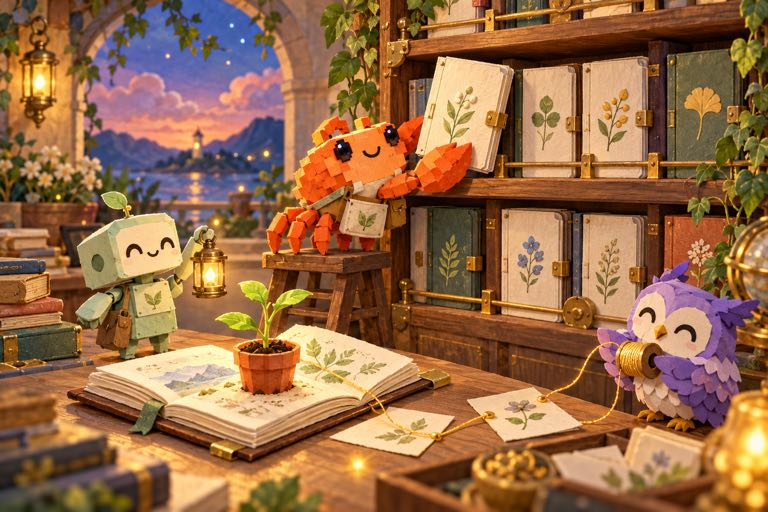

*Keep the lineage, the failed experiments and the original artifacts. A new idea should add evidence.*

<a id="instyle-limitations"></a>

## What we contribute, what remains uncertain

Our **shared-prompt Gaussian model** estimates a shared nuisance effect instead of assuming a sample mean is a noiseless prompt estimate. Pair/triple posterior marginalization is exact **under that fitted model and its label constraints**; it is not a proof that an inferred group is correct. Larger-group cavity inference is approximate. Our **two-stage adapters** use our own public pool construction, training implementation and seeds; their v3 public increment was 0.593 to 0.599. Version 6 rebuilt branch A on the stronger part-two members and gave every member a Gaussian head; the end token of each checkpoint is checked against the training fit on 64 training rows before any test passage is scored, because the hosted Qwen3 tokenizer's end token differs from the one the checkpoints were trained with. Those are measured changes to the complete notebook, not isolated causal estimates for every component.

External passages increase coverage but introduce generation-route and collection shifts. A pool label is a publisher claim, not independent proof of which endpoint generated the text. Frozen encoders may still encode topic, and a centred feature is not automatically an invariant style representation. An ensemble can also amplify correlated errors.

An independent next question is **group reliability before group subtraction**: when lexical and representation-based neighborhoods disagree, should a passage retain more singleton evidence rather than inherit a hard cluster decision? A useful experiment would hold the representations fixed, fit a reliability rule only inside training folds, and test incorrect merges and missing group members as well as intact prompts. This is a proposed ablation, **not an enabled feature or a claimed result**. Another necessary ablation compares current balancing with a train-only prior correction under shifted class mixtures, using exactly the same unbalanced probabilities.

For an additional component to enter our research pipeline, its nested gain must be at least +0.008 with a positive lower 95% paired prompt-bootstrap bound on **both** grouped fold schemes, followed by the strongest full-stack comparison, falsification checks, sealed confirmation and a native offline rerun. Full-prompt CV, synthetic demonstrations and public leaderboard exploration answer different questions; none alone proves transfer to the final private test.

<a id="instyle-reuse"></a>

## Reuse and credit

The original contributor table above remains part of the notebook. In particular, this edition builds on [Travis Nguyen's in-style stack](https://www.kaggle.com/code/vnton37nguyn/ntl-lora-instyle-0-563), [Nishant Dahal's two-stage public-pool recipe](https://www.kaggle.com/code/nishantdahal/two-stage-lora-on-the-public-pool) and its [part two](https://www.kaggle.com/code/nishantdahal/two-stage-lora-part-two) with its public [checkpoints and pool](https://www.kaggle.com/datasets/nishantdahal/ntl-handwriting-blend), [Кирилл Тымчишин's two-branch integration](https://www.kaggle.com/code/kirilltym/0-600-teach-the-model-remove-the-prompt), and [Joseph Adamski's early-layer investigation](https://www.kaggle.com/code/josephadamski91/two-stage-lora-atlas-and-early-layers). The ATLAS component from the last source is not enabled here. Lucas Boesen, Yang Kuang Ou, Vladislav Lavrentev, Zbigniew Kirchner, pjmathematician and the public data contributors retain credit for their respective components and artifacts.

The [competition data](https://www.kaggle.com/competitions/name-that-llm/data) and [Nishant's aggregate public pools](https://www.kaggle.com/datasets/nishantdahal/ntl-handwriting-blend) are CC BY-SA 4.0; the audited upstream passage collections include CC BY 4.0 and CC BY-SA 4.0. Those data licenses do **not** automatically relicense separately published code, model weights or adapters. Consult each linked artifact's current license and terms when redistributing it; the notebook's attached inputs preserve the upstream identities.

Five original illustrations were generated with the built-in image-generation tool for this edition. Their full prompts, original PNGs, delivery previews and hashes are preserved with the project. The brand-mascot scene is playful fan art and implies no endorsement. Technical diagrams were written deterministically from the actual code and validation protocol; generated imagery supplies no equations, measurements or score claims.